# Deep dive: LEDA 4572013 (HS 1248+3523), the #2 line-ratio outlier

**Question.** The BPT outlier pipeline ranked this galaxy #2 of the 8 stable candidates. Its most extreme feature was a very low $[\mathrm{N\,II}]/\mathrm{H}\alpha$ ($\log = -1.58$, a 4.75-IQR deviation from the 10,000-galaxy sample). Is it a genuinely unusual object, or what an outlier detector produces when it meets a normal member of a population that the sample under-represents?

**Approach.** Collect what is publicly known about this one object (SDSS spectrum and MPA-JHU tables, ALFALFA H I, AllWISE, Legacy Survey imaging, SDSS neighbours, SIMBAD and the literature), write the hypotheses and decision rules down, and test each against **matched controls** drawn from the same archives. Where a test could be fooled by selection, I check that explicitly.

**Bottom line** (written after reading the numbers generated below):

1. **The object is real and is not an AGN.** [O III] $\lambda$4363 is detected at S/N $\approx$ 13 both in the MPA-JHU catalogue and in my independent joint fit of the raw spectrum. No line sits near a strong sky line or under a masked pixel, and the mid-IR colour is $W1-W2 = 0.23$.
2. **It is a low-mass, low-metallicity starburst dwarf**: $\log M_\star \approx 8.1$, direct-T$_e$ $12+\log(\mathrm{O/H}) = 7.94 \pm 0.04$ ($\approx 0.18\,Z_\odot$), EW(H$\alpha$) = 259 Å (95th percentile at its mass). It is **not** extremely metal-poor (that threshold is 7.35).
3. **Most of the detector's flag is context.** $[\mathrm{N\,II}]/\mathrm{H}\alpha$ goes from the 0.02nd percentile in the pipeline's sample to the 2nd among mass-matched star-forming galaxies. No robust metallicity deficit survives method-matched controls.
4. **What remains is a low N/O**: 0.24 dex below controls at the same O/H (2.9th percentile), enough to account for the $[\mathrm{N\,II}]/\mathrm{H}\alpha$ offset. It is robust to the obvious selection check, but it is one 3% result among about a dozen comparisons, so it is not significant on its own.
5. **Its high H I-to-stellar-mass ratio is what an H I detection at 146 Mpc selects for**; at a typical ratio the galaxy would have S/N $\approx$ 1.4 and be undetectable. It cannot be called anomalous.
6. **No hypothesis clears the 2.5% bar I set.** As a statistical anomaly it does not stand up; as a follow-up target for N/O and H I it is reasonable.

*Data retrieved 2026-11-20. Archive queries are cached in `data/deep_dive/`, which is not tracked in git; the notebook fetches whatever is missing, so a fresh clone needs network access once (see Section 2).*

## 1. Hypotheses and decision rules

| | Hypothesis | Supported if | Section |
|---|---|---|---|
| **H0** | **Context only**: a normal dwarf starburst, flagged because the pipeline sample is dominated by massive galaxies | its extremeness largely disappears against mass-matched star-forming galaxies | 3 |
| **H1** | **Metal-poor for its mass** (not merely low-mass) | O/H below the central 95% of controls matched in mass (and sSFR), or direct-T$_e$ O/H $< 7.35$ (the conventional "extremely metal-poor" cut, about 1/20 $Z_\odot$ on the 8.69 scale) | 5, 6 |
| **H2** | **Young, burst-dominated** | EW(H$\alpha$) in the top 2.5% at fixed mass | 6 |
| **H3** | **Nitrogen-poor** (low N/O at fixed O/H) | log N/O in the lowest 2.5% of controls at the same O/H | 5 |
| **H4** | **Gas-rich beyond the norm** (accretion-fed?) | log M$_\mathrm{HI}$/M$_\star$ in the top 2.5% *and* not explained by the H I detection limit | 7 |
| **H5** | **Artefact or AGN contamination** | 4363 not recovered independently; sky or mask problems; mid-IR AGN colours | 4, 8 |

**Decision rule.** For each test, the tail probability $p$ in the hypothesised direction: $p \le 0.025$ is *supported*, $0.025 < p \le 0.10$ is *weak / suggestive*, $p > 0.10$ is *not supported*.

**Honest caveats about the rules.**
- I looked at preliminary numbers while building this notebook, so these thresholds are conventional (roughly "2$\sigma$"), **not** blind pre-registrations.
- I run about a dozen comparisons. At a 2.5% threshold one expects a spurious "hit" about 0.3 times by chance, and a single 2.9% result is not evidence by itself.
- The tests are correlated (metallicity, N/O and sSFR are physically linked), so p-values should not be multiplied.

**What this is not.** A discovery claim. Nothing here is a new observation: it is a careful reading of existing archival data on one object.

## 2. Setup and data sources

Everything below reads from the cache in `data/deep_dive/`; `src/deep_dive_data.py` fills it from the archives (SkyServer DR17, SAS, VizieR, SIMBAD, Legacy Survey, Crossref). The cache is not tracked in git: any missing file is fetched on first use (network access needed once), and deleting a cache file re-fetches it.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from astropy.io import fits
from astropy.coordinates import SkyCoord
import astropy.units as u
from astropy.cosmology import Planck18 as cosmo
from IPython.display import display, Image

warnings.filterwarnings("ignore", category=RuntimeWarning)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import deep_dive_data as dd
import deep_dive_physics as ph
from bpt_math import kauffmann_boundary, kewley_boundary
from query_data import MPA_JHU_ERR_SCALE

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
C_T, C_CTRL, C_ALT = "#d62728", "#7f8c9a", "#1f77b4"

T = dd.TARGET
tab = dd.target_tables()
L, E, P, S, INFO = (tab[k].iloc[0] for k in ["lines", "extra", "photo", "spec", "info"])
z = T["z"]
D_L = cosmo.luminosity_distance(z).value                       # Mpc
KPC_PER_ARCSEC = cosmo.kpc_proper_per_arcmin(z).value / 60
R = {}   # results collected for the verdict table (section 11)

prov = pd.Series({
    "name": f"{T['name']} = {', '.join(T['alt_names'])}",
    "specObjID": T["specObjID"], "plate-mjd-fiber": f"{T['plate']}-{T['mjd']}-{T['fiberID']}",
    "RA, Dec (deg)": f"{T['ra']:.5f}, {T['dec']:+.5f}", "z": z,
    "D_L (Planck18)": f"{D_L:.1f} Mpc", "scale": f"{KPC_PER_ARCSEC:.3f} kpc/arcsec",
    "SDSS fibre (3 arcsec)": f"{3 * KPC_PER_ARCSEC:.2f} kpc across",
    "SDSS spec class / subclass": f"{S['class']} / {S['subClass']}",
    "SDSS targeting": f"primTarget={S['primTarget']} (66 = 64 + 2; bit meanings to be checked against the SDSS datamodel)",
    "MPA-JHU log M* (total, p16-p50-p84)": f"{E.lgm_tot_p16:.2f} - {E.lgm_tot_p50:.2f} - {E.lgm_tot_p84:.2f}",
    "MPA-JHU 12+log(O/H) (p16-p50-p84)": f"{E.oh_p16:.2f} - {E.oh_p50:.2f} - {E.oh_p84:.2f}",
    "MPA-JHU bptclass": int(E.bptclass),
    "Galactic E(B-V) (SFD)": f"{INFO.e_bv_sfd:.3f}",
})
display(prov.to_frame("value"))

,value
name,"LEDA 4572013 = HS 1248+3523, AGC 227547, SDSS ..."
specObjID,2237320683103217664
plate-mjd-fiber,1987-53765-573
"RA, Dec (deg)","192.81909, +35.11345"
z,0.033379
D_L (Planck18),151.6 Mpc
scale,0.688 kpc/arcsec
SDSS fibre (3 arcsec),2.07 kpc across
SDSS spec class / subclass,GALAXY / STARBURST
SDSS targeting,primTarget=66 (66 = 64 + 2; bit meanings to be...


## 3. Why did the detector flag it? (context, not physics)

The pipeline's features were scaled against the project's 10,000-galaxy sample, which is flux-limited and dominated by massive galaxies. A fairer question is how unusual this object is among **star-forming galaxies of similar stellar mass**. The control below is the SDSS/MPA-JHU star-forming population (`bptclass = 1`, with a measured O/H), restricted to ±0.3 dex in stellar mass around this object.

,target,percentile in 10k sample,percentile in mass-matched SF control (N=1412)
feature,,,
log [N II]/Ha,-1.58,0.02,2.05
log [O III]/Hb,0.61,97.51,89.66
log Ha/Hb (Balmer decr.),0.49,7.50,48.44
log EW(Ha),2.41,99.72,94.69


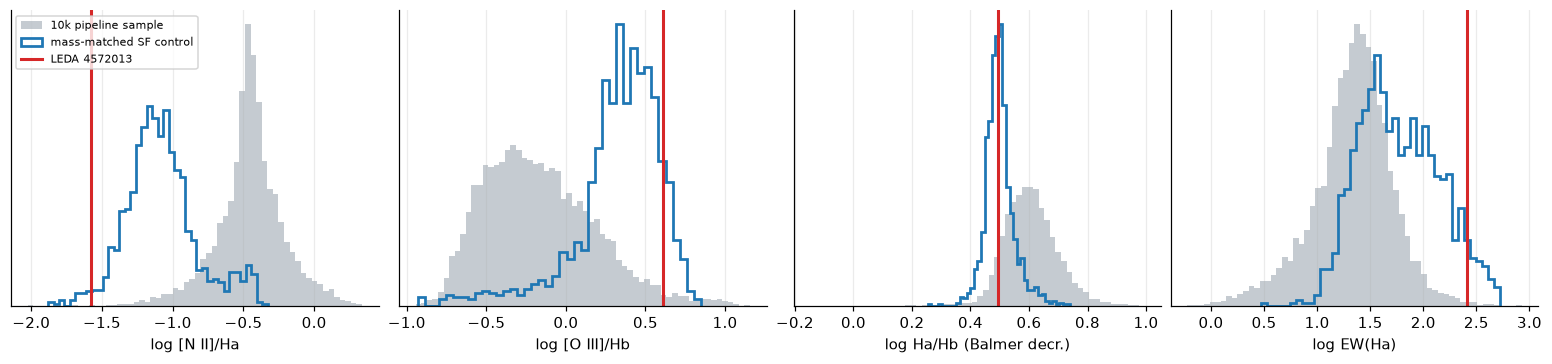

Target: z=0.033, r(model)=17.68 (SDSS main-sample limit is r_petro<17.77), |  sample median z = 0.077


In [2]:
s10k = pd.read_csv(ROOT / "data" / "sdss_bpt_sample.csv")
s10k["log_ew_ha"] = np.log10(-s10k.h_alpha_eqw)
s10k["log_bd"] = np.log10(s10k.h_alpha_flux / s10k.h_beta_flux)
me = s10k[s10k.specObjID == T["specObjID"]].iloc[0]

g = dd.mzr_control()
lm = float(E.lgm_tot_p50)
ctrl = g[g.lgm_tot_p50.between(lm - 0.3, lm + 0.3)].copy()
ctrl["log_nii_ha"] = np.log10(ctrl.nii_6584_flux / ctrl.h_alpha_flux)
ctrl["log_oiii_hb"] = np.log10(ctrl.oiii_5007_flux / ctrl.h_beta_flux)
ctrl["log_ew_ha"] = np.log10(-ctrl.h_alpha_eqw)
ctrl["log_bd"] = np.log10(ctrl.h_alpha_flux / ctrl.h_beta_flux)

feats = {"log_nii_ha": "log [N II]/Ha", "log_oiii_hb": "log [O III]/Hb", "log_bd": "log Ha/Hb (Balmer decr.)", "log_ew_ha": "log EW(Ha)"}
pct = lambda arr, v: float((np.asarray(arr) < v).mean())
rows = []
for k, lab in feats.items():
    rows.append({"feature": lab, "target": me[k],
                 "percentile in 10k sample": 100 * pct(s10k[k], me[k]),
                 f"percentile in mass-matched SF control (N={len(ctrl)})": 100 * pct(ctrl[k], me[k])})
ctx = pd.DataFrame(rows).set_index("feature")
display(ctx.round(2))
R["ctx_nii_pct_10k"], R["ctx_nii_pct_ctrl"] = ctx.iloc[0, 1], ctx.iloc[0, 2]

fig, ax = plt.subplots(1, 4, figsize=(14, 3.2), constrained_layout=True)
for a, (k, lab) in zip(ax, feats.items()):
    a.hist(s10k[k], bins=60, density=True, color=C_CTRL, alpha=0.45, label="10k pipeline sample")
    a.hist(ctrl[k], bins=40, density=True, histtype="step", color=C_ALT, lw=1.8, label="mass-matched SF control")
    a.axvline(me[k], color=C_T, lw=2, label="LEDA 4572013")
    a.set_xlabel(lab); a.set_yticks([])
ax[0].legend(fontsize=7, loc="upper left")
plt.show()
print(f"Target: z={z:.3f}, r(model)={P.modelMag_r:.2f} (SDSS main-sample limit is r_petro<17.77), "
      f"|  sample median z = {s10k.z.median():.3f}")

**Reading.** Against the pipeline's 10k sample the object is extreme in $[\mathrm{N\,II}]/\mathrm{H}\alpha$ (0.02nd percentile) and EW(H$\alpha$) (99.7th). Against star-forming galaxies of the **same stellar mass**, $[\mathrm{N\,II}]/\mathrm{H}\alpha$ moves to the 2nd percentile and EW(H$\alpha$) to the 94.7th. The Balmer decrement is typical (48th) and $[\mathrm{O\,III}]/\mathrm{H}\beta$ is high but unremarkable (90th).

So the feature-scaling made a dwarf look exotic: dwarfs are rare in a flux-limited sample dominated by massive galaxies (sample median $z = 0.077$; this object is at $z = 0.033$). It also sits right at the spectroscopic flux limit ($r = 17.68$ vs 17.77): at this distance SDSS only sees the bright end of the dwarf population, a Malmquist-type selection to keep in mind through the rest of the notebook.

This is the context shift of **H0**, but not all of the extremeness disappears. A low $[\mathrm{N\,II}]/\mathrm{H}\alpha$ residual remains at about the 2% level, which Sections 5 and 6 try to explain. (The mass-matched control is itself bimodal in $[\mathrm{N\,II}]/\mathrm{H}\alpha$, with a second population near $-0.4$; that matters again in Section 6.)

## 4. Is the spectrum real? (hypothesis H5)

I download the raw SDSS spectrum and fit the lines myself, independently of MPA-JHU. Blended lines are fit **jointly** (common width and velocity offset, atomic ratios tied for [O III] 5007/4959 = 2.98 and [N II] 6584/6548 = 3.05), on a linear local continuum. Flux calibration differs between the data release MPA-JHU used and the current reduction, so absolute fluxes are not expected to match; **line ratios** are what the physics uses.

In [3]:
hdul = fits.open(dd.spectrum_path())
sp = hdul[1].data
wave_obs = np.asarray(10 ** sp["loglam"], float)
rest = wave_obs / (1 + z)
flux = np.asarray(sp["flux"], float) * (1 + z)          # integrates (over rest wavelength) to the observed-frame line flux
ivar = np.asarray(sp["ivar"], float) / (1 + z) ** 2
specobj = hdul[2].data[0]
print(f"SN_MEDIAN_ALL = {specobj['SN_MEDIAN_ALL']:.1f}, ZWARNING = {specobj['ZWARNING']}, "
      f"rest-frame coverage {rest.min():.0f}-{rest.max():.0f} A")

fits_ = {}
r = ph.fit_multiline(rest, flux, ivar, [4340.47, 4363.21], (4300, 4400)); fits_["hgamma"], fits_["oiii_4363"] = r[0], r[1]; fits_["_win4363"] = r[0]
r = ph.fit_multiline(rest, flux, ivar, [4861.33], (4800, 4920)); fits_["hbeta"] = r[0]; fits_["_winHb"] = r[0]
r = ph.fit_multiline(rest, flux, ivar, [5006.84, 4958.91], (4930, 5040), tie={1: (0, 1 / 2.98)}); fits_["oiii_5007"], fits_["oiii_4959"] = r; fits_["_winO3"] = r[0]
r = ph.fit_multiline(rest, flux, ivar, [6562.80, 6583.45, 6548.05], (6500, 6620), tie={2: (1, 1 / 3.05)}); fits_["halpha"], fits_["nii_6584"] = r[0], r[1]; fits_["_winHa"] = r[0]
r = ph.fit_multiline(rest, flux, ivar, [3726.03, 3728.82], (3690, 3770)); fits_["oii_3726"], fits_["oii_3729"] = r; fits_["_winO2"] = r[0]

mpa_flux = {"oii_3726": L.oii_3726_flux, "oii_3729": L.oii_3729_flux, "hgamma": L.h_gamma_flux, "oiii_4363": L.oiii_4363_flux,
            "hbeta": L.h_beta_flux, "oiii_4959": L.oiii_4959_flux, "oiii_5007": L.oiii_5007_flux,
            "halpha": L.h_alpha_flux, "nii_6584": L.nii_6584_flux}
mpa_err = {"oii_3726": L.oii_3726_flux_err, "oii_3729": L.oii_3729_flux_err, "hgamma": L.h_gamma_flux_err,
           "oiii_4363": L.oiii_4363_flux_err, "hbeta": L.h_beta_flux_err * MPA_JHU_ERR_SCALE["h_beta"],
           "oiii_4959": L.oiii_4959_flux_err, "oiii_5007": L.oiii_5007_flux_err * MPA_JHU_ERR_SCALE["oiii_5007"],
           "halpha": L.h_alpha_flux_err * MPA_JHU_ERR_SCALE["h_alpha"], "nii_6584": L.nii_6584_flux_err * MPA_JHU_ERR_SCALE["nii_6584"]}
tbl = pd.DataFrame([{"line": k, "own flux": fits_[k]["flux"], "own err": fits_[k]["flux_err"], "own S/N": fits_[k]["snr"],
                     "MPA flux": mpa_flux[k], "MPA S/N (formal)": mpa_flux[k] / mpa_err[k],
                     "own/MPA": fits_[k]["flux"] / mpa_flux[k]} for k in mpa_flux]).set_index("line")
display(tbl.round(2))
print("Reduced chi2 of the joint fits:", {k.strip("_"): round(v["chi2"], 2) for k, v in fits_.items() if k.startswith("_")})
sc = tbl["own/MPA"].median()
print(f"Median absolute-flux ratio own/MPA = {sc:.2f} (calibration; cancels in ratios).")

def ratios(f):
    return pd.Series({"[O III]/Hb": (f["oiii_5007"] + f["oiii_4959"]) / f["hbeta"], "Ha/Hb": f["halpha"] / f["hbeta"],
                      "[N II]/Ha": f["nii_6584"] / f["halpha"], "[O II]/Hb": (f["oii_3726"] + f["oii_3729"]) / f["hbeta"],
                      "R=(5007+4959)/4363": (f["oiii_5007"] + f["oiii_4959"]) / f["oiii_4363"],
                      "[O II] 3729/3726": f["oii_3729"] / f["oii_3726"]})
own_flux = {k: v["flux"] for k, v in fits_.items() if not k.startswith("_")}
rt = pd.DataFrame({"own fit": ratios(own_flux), "MPA-JHU": ratios(mpa_flux)}); rt["difference %"] = 100 * (rt["own fit"] / rt["MPA-JHU"] - 1)
display(rt.round(3))
R["snr_4363_own"] = fits_["oiii_4363"]["snr"]

SN_MEDIAN_ALL = 12.8, ZWARNING = 0, rest-frame coverage 3693-8917 A


,own flux,own err,own S/N,MPA flux,MPA S/N (formal),own/MPA
line,,,,,,
oii_3726,637.19,19.26,33.09,559.31,55.92,1.14
oii_3729,956.54,22.93,41.72,635.85,59.79,1.50
hgamma,309.22,6.57,47.06,258.38,59.10,1.20
oiii_4363,45.68,3.63,12.60,31.37,12.93,1.46
hbeta,732.05,12.08,60.60,582.22,48.81,1.26
oiii_4959,1056.86,13.83,76.44,822.54,97.67,1.28
oiii_5007,3149.45,41.20,76.44,2372.39,70.80,1.33
halpha,2417.76,35.07,68.94,1811.07,50.50,1.33
nii_6584,63.04,3.71,16.99,47.87,15.53,1.32


Reduced chi2 of the joint fits: {'win4363': 1.25, 'winHb': 2.11, 'winO3': 3.64, 'winHa': 3.12, 'winO2': 1.9}
Median absolute-flux ratio own/MPA = 1.32 (calibration; cancels in ratios).


,own fit,MPA-JHU,difference %
[O III]/Hb,5.746,5.488,4.709
Ha/Hb,3.303,3.111,6.175
[N II]/Ha,0.026,0.026,-1.346
[O II]/Hb,2.177,2.053,6.055
R=(5007+4959)/4363,92.077,101.845,-9.590
[O II] 3729/3726,1.501,1.137,32.049


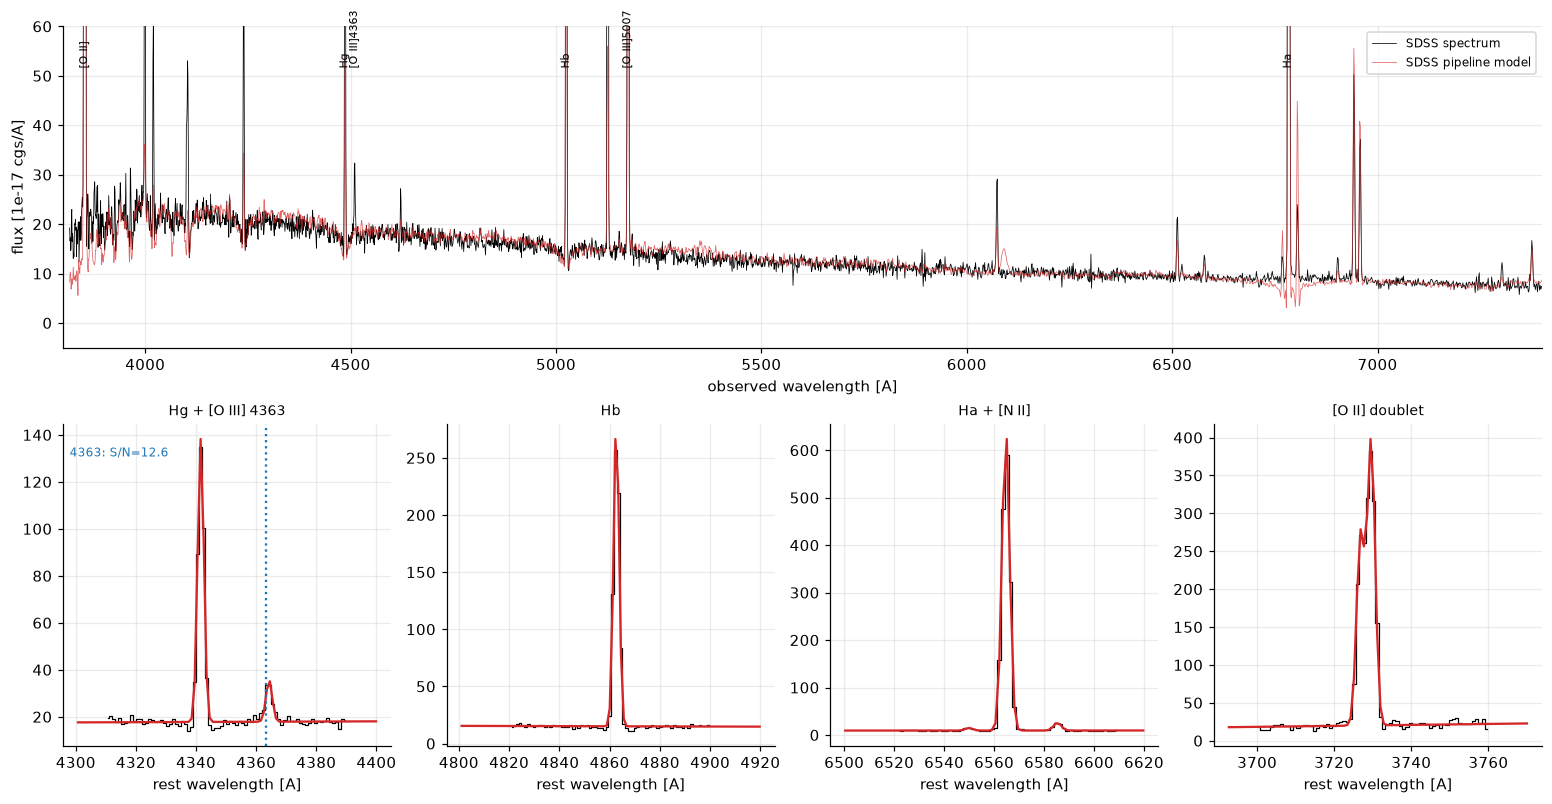

,observed [A],median sky in +-4A,median object flux,frac pixels with AND-mask,nearest strong sky line,distance [A]
line,,,,,,
[O II] 3727,3851.82,4.10,252.800003,0.0,Hg I 4358,506.51
Hg,4485.35,5.59,35.150002,0.0,Hg I 4358,127.02
[O III] 4363,4508.85,6.01,21.650000,0.0,Hg I 4358,150.52
Hb,5023.60,4.96,80.730003,0.0,Hg I 5461,437.14
[O III] 5007,5173.96,3.95,318.480011,0.0,Hg I 5461,286.78
Ha,6781.86,4.13,232.699997,0.0,[O I] 6364,418.08
[N II] 6584,6803.20,3.96,16.040001,0.0,[O I] 6364,439.42


In [4]:
fig = plt.figure(figsize=(14, 7.2), constrained_layout=True)
gs = fig.add_gridspec(2, 4)
ax0 = fig.add_subplot(gs[0, :])
ax0.plot(wave_obs, sp["flux"], lw=0.5, color="k", label="SDSS spectrum")
ax0.plot(wave_obs, sp["model"], lw=0.5, color=C_T, alpha=0.7, label="SDSS pipeline model")
ax0.set_xlim(3800, 7400); ax0.set_ylim(-5, 60); ax0.set_xlabel("observed wavelength [A]"); ax0.set_ylabel("flux [1e-17 cgs/A]"); ax0.legend(fontsize=8)
for k, w0 in [("[O II]", 3727.4), ("Hg", 4340.47), ("[O III]4363", 4363.21), ("Hb", 4861.33), ("[O III]5007", 5006.84), ("Ha", 6562.8)]:
    ax0.annotate(k, (w0 * (1 + z), 52), fontsize=7, ha="center", rotation=90)
panels = [("_win4363", (4310, 4390), "Hg + [O III] 4363"), ("_winHb", (4820, 4900), "Hb"), ("_winHa", (6520, 6610), "Ha + [N II]"), ("_winO2", (3700, 3760), "[O II] doublet")]
for j, (key, xl, ttl) in enumerate(panels):
    a = fig.add_subplot(gs[1, j]); w = fits_[key]
    m = (rest > xl[0]) & (rest < xl[1])
    a.step(rest[m], flux[m], where="mid", color="k", lw=0.8)
    a.plot(w["x"], w["yfit"], color=C_T, lw=1.5)
    a.set_title(ttl, fontsize=9); a.set_xlabel("rest wavelength [A]")
    if key == "_win4363":
        a.axvline(4363.21, color=C_ALT, ls=":")
        a.annotate(f"4363: S/N={fits_['oiii_4363']['snr']:.1f}", (0.02, 0.9), xycoords="axes fraction", fontsize=8, color=C_ALT)
plt.show()

# contamination checks: sky lines and pixel masks at each line
sky = np.asarray(sp["sky"], float); andmask = np.asarray(sp["and_mask"])
known_sky = {"Hg I 4358": 4358.33, "Hg I 5461": 5460.74, "[O I] 5577": 5577.34, "Na I 5890": 5889.95, "Na I 5896": 5895.92, "[O I] 6300": 6300.30, "[O I] 6364": 6363.78}
rows = []
for name, w0 in {"[O II] 3727": 3727.4, "Hg": 4340.47, "[O III] 4363": 4363.21, "Hb": 4861.33, "[O III] 5007": 5006.84, "Ha": 6562.8, "[N II] 6584": 6583.45}.items():
    wo = w0 * (1 + z); m = np.abs(wave_obs - wo) < 4
    nearest = min(known_sky, key=lambda k: abs(known_sky[k] - wo))
    rows.append({"line": name, "observed [A]": wo, "median sky in +-4A": np.median(sky[m]), "median object flux": np.median(sp["flux"][m]),
                 "frac pixels with AND-mask": float((andmask[m] != 0).mean()),
                 "nearest strong sky line": nearest, "distance [A]": abs(known_sky[nearest] - wo)})
display(pd.DataFrame(rows).set_index("line").round(2))

**Reading.** The joint fits recover every line at S/N $\ge$ 12, including the faint [O III] $\lambda$4363 (own S/N = 12.6 against MPA-JHU's formal 12.9) and [N II] $\lambda$6584 (S/N = 17). The 4363 window fits cleanly (reduced $\chi^2 = 1.25$): the line is plainly visible in the bottom-left panel, to the right of the much stronger H$\gamma$.

- **Calibration.** My absolute fluxes are about 1.3$\times$ MPA-JHU's for every line. I believe this is a spectrophotometric-calibration difference between the data releases, but I did not verify that. Line ratios agree to 1-6%, with two exceptions: $R = (5007+4959)/4363$ differs by 10% and feeds a ~5% difference in T$_e$ (Section 5), and the split of the [O II] doublet differs (3729/3726 = 1.50 in my fit vs 1.14 in MPA-JHU), although the *sum* agrees once the calibration factor is allowed for, and only the sum is used. I carry the differences forward as a systematic instead of choosing a winner.
- **Fit quality.** The bright-line windows have reduced $\chi^2$ of 1.9-3.6, so a single Gaussian does not capture the line wings perfectly. That affects fluxes at roughly the percent level, below the 5% own-vs-MPA differences.
- **Contamination.** No line is within 120 Å of a strong sky line and no pixel under any line carries a pipeline mask. **H5 (artefact) is not supported.**

## 5. Direct-Te abundances (H1, H3)

The [O III] 4363/5007 ratio measures the electron temperature, which gives an oxygen abundance without leaning on strong-line calibrations. Equations are in `src/deep_dive_physics.py` (unit-tested; coefficients follow Izotov et al. 2006 and Osterbrock 1989). Because I wrote those coefficients from memory, the next cells **validate the code on ~800 other galaxies with a detected 4363 line** before the target's numbers are trusted.

In [5]:
def to_f(f):
    return {"oii_3727": f["oii_3726"] + f["oii_3729"], "hbeta": f["hbeta"], "halpha": f["halpha"], "oiii_4363": f["oiii_4363"],
            "oiii_4959": f["oiii_4959"], "oiii_5007": f["oiii_5007"], "nii_6584": f["nii_6584"]}

def to_err(e):
    return {"oii_3727": np.hypot(e["oii_3726"], e["oii_3729"]), "hbeta": e["hbeta"], "halpha": e["halpha"], "oiii_4363": e["oiii_4363"],
            "oiii_4959": e["oiii_4959"], "oiii_5007": e["oiii_5007"], "nii_6584": e["nii_6584"]}

own_err = {k: v["flux_err"] for k, v in fits_.items() if not k.startswith("_")}
res = {}
for lab, f, e in [("own fit", own_flux, own_err), ("MPA-JHU fluxes", mpa_flux, mpa_err)]:
    d = ph.direct_abundances(to_f(f)); mc = ph.direct_abundances_mc(to_f(f), to_err(e), n=2000)
    res[lab] = {"E(B-V) from Ha/Hb": d["ebv"], "Te[O III] [K]": mc["Te_OIII"][0], "Te lo": mc["Te_OIII"][1], "Te hi": mc["Te_OIII"][2],
                "12+log(O/H)": mc["OH"][0], "OH lo": mc["OH"][1], "OH hi": mc["OH"][2],
                "log(N/O)": mc["logNO"][0], "NO lo": mc["logNO"][1], "NO hi": mc["logNO"][2],
                "O+ fraction": d["O2_frac"], "Te[O III] Perez-Montero17 [K]": d["t3_empirical_PM17"] * 1e4}
resdf = pd.DataFrame(res)
display(resdf.round(3))

# sensitivity to the assumed electron density, and to Balmer-decrement dust correction
for ne in (10, 100, 500):
    d = ph.direct_abundances(to_f(own_flux), ne=ne); print(f"n_e={ne:4d} cm^-3: 12+log(O/H)={d['OH']:.3f}  log(N/O)={d['logNO']:.3f}")
for ebv in (0.0, 0.10, 0.20):
    d = ph.direct_abundances(to_f(own_flux), ebv=ebv); print(f"E(B-V)={ebv:.2f}: 12+log(O/H)={d['OH']:.3f}  log(N/O)={d['logNO']:.3f}")

# independent check of E(B-V) using Hgamma/Hb (case B intrinsic 0.468)
kg, kb = ph.ccm89_k(ph.LINES["hgamma"]), ph.ccm89_k(ph.LINES["hbeta"])
for lab, f in [("own fit", own_flux), ("MPA", mpa_flux)]:
    print(f"E(B-V) from Hg/Hb ({lab}): {2.5 / (kg - kb) * np.log10(0.468 / (f['hgamma'] / f['hbeta'])):.3f}   from Ha/Hb: {float(ph.ebv_from_balmer(f['halpha'], f['hbeta'])):.3f}")

ZSUN = 8.69   # Asplund et al. 2009
oh_own, oh_mpa = res["own fit"]["12+log(O/H)"], res["MPA-JHU fluxes"]["12+log(O/H)"]
print(f"\nDirect-Te 12+log(O/H) = {oh_own:.2f} (own) / {oh_mpa:.2f} (MPA fluxes)  ->  Z = {10 ** (oh_own - ZSUN):.2f} / {10 ** (oh_mpa - ZSUN):.2f} Zsun; "
      f"extremely-metal-poor threshold is 12+log(O/H) < 7.35, i.e. {oh_own - 7.35:.2f} dex above it.")
R["OH_direct_own"], R["OH_direct_mpa"], R["NO_own"], R["NO_mpa"] = oh_own, oh_mpa, res["own fit"]["log(N/O)"], res["MPA-JHU fluxes"]["log(N/O)"]

,own fit,MPA-JHU fluxes
E(B-V) from Ha/Hb,0.146,0.085
Te[O III] [K],13896.795,13132.451
Te lo,13453.894,12737.843
Te hi,14378.990,13556.925
12+log(O/H),7.938,7.973
OH lo,7.903,7.939
OH hi,7.975,8.011
log(N/O),-1.654,-1.617
NO lo,-1.689,-1.655
NO hi,-1.621,-1.579


n_e=  10 cm^-3: 12+log(O/H)=7.934  log(N/O)=-1.653
n_e= 100 cm^-3: 12+log(O/H)=7.939  log(N/O)=-1.653
n_e= 500 cm^-3: 12+log(O/H)=7.961  log(N/O)=-1.653
E(B-V)=0.00: 12+log(O/H)=7.963  log(N/O)=-1.536
E(B-V)=0.10: 12+log(O/H)=7.946  log(N/O)=-1.616
E(B-V)=0.20: 12+log(O/H)=7.931  log(N/O)=-1.697
E(B-V) from Hg/Hb (own fit): 0.197   from Ha/Hb: 0.146
E(B-V) from Hg/Hb (MPA): 0.102   from Ha/Hb: 0.085

Direct-Te 12+log(O/H) = 7.94 (own) / 7.97 (MPA fluxes)  ->  Z = 0.18 / 0.19 Zsun; extremely-metal-poor threshold is 12+log(O/H) < 7.35, i.e. 0.59 dex above it.


807 control galaxies with valid direct-Te abundances
direct minus MPA-JHU 12+log(O/H): median -0.22 dex, scatter 0.26  (direct-Te sits below strong-line/model calibrations; cf. Kewley & Ellison 2008)
log N/O at 12+log(O/H)<8.2: all -1.38 (N=590); with [N II] S/N>=5 -1.37 (N=585, 16-84%: -1.52..-1.18)
direct-Te controls within +-0.3 dex of log M*=8.13: N=99, median 12+log(O/H)=8.09, 16-84%: 7.92..8.21; target 7.97 = -0.12 dex, percentile 22.2 (caveat: 4363-selected controls are biased toward hot, metal-poor gas, which makes this comparison conservative)


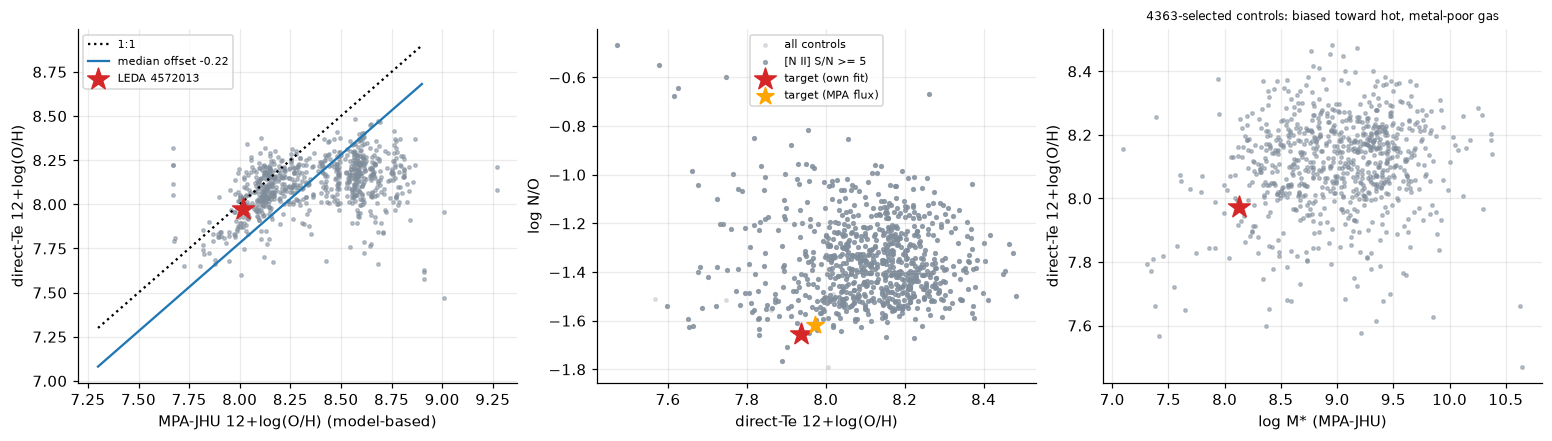

In [6]:
# ---- validate the Te code on the control galaxies with a detected [O III] 4363
c = dd.te_control()
rows = []
for _, r_ in c.iterrows():
    f = {"oii_3727": r_.oii_3726_flux + r_.oii_3729_flux, "hbeta": r_.h_beta_flux, "halpha": r_.h_alpha_flux, "oiii_4363": r_.oiii_4363_flux,
         "oiii_4959": r_.oiii_4959_flux, "oiii_5007": r_.oiii_5007_flux, "nii_6584": r_.nii_6584_flux}
    try:
        a_ = ph.direct_abundances(f)
    except Exception:
        continue
    rows.append({"specObjID": r_.specObjID, "OH": a_["OH"], "logNO": a_["logNO"], "Te": a_["Te_OIII"],
                 "nii_snr": r_.nii_6584_flux / r_.nii_6584_flux_err})
ca = pd.DataFrame(rows).merge(c[["specObjID", "lgm_tot_p50", "oh_p50", "h_alpha_eqw"]], on="specObjID")
ca = ca[np.isfinite(ca.OH) & np.isfinite(ca.logNO) & (ca.Te > 5000) & (ca.Te < 30000)].reset_index(drop=True)
mm = ca.oh_p50 > 0
off = (ca.OH[mm] - ca.oh_p50[mm])
print(f"{len(ca)} control galaxies with valid direct-Te abundances")
print(f"direct minus MPA-JHU 12+log(O/H): median {off.median():+.2f} dex, scatter {off.std():.2f}  (direct-Te sits below strong-line/model calibrations; cf. Kewley & Ellison 2008)")
hiS = ca[ca.nii_snr >= 5]
plateau = hiS[hiS.OH < 8.2]
print(f"log N/O at 12+log(O/H)<8.2: all {ca[ca.OH < 8.2].logNO.median():.2f} (N={int((ca.OH < 8.2).sum())}); "
      f"with [N II] S/N>=5 {plateau.logNO.median():.2f} (N={len(plateau)}, 16-84%: {plateau.logNO.quantile(.16):.2f}..{plateau.logNO.quantile(.84):.2f})")
R["ctrl_te_n"], R["ctrl_offset"] = len(ca), float(off.median())

# like-for-like H1 test: direct-Te target vs direct-Te controls at the same stellar mass
dsub = ca[ca.lgm_tot_p50.between(lm - 0.3, lm + 0.3)]
R["H1d_pct"], R["H1d_dex"], R["H1d_n"] = pct(dsub.OH, oh_mpa), oh_mpa - dsub.OH.median(), len(dsub)
print(f"direct-Te controls within +-0.3 dex of log M*={lm:.2f}: N={len(dsub)}, median 12+log(O/H)={dsub.OH.median():.2f}, "
      f"16-84%: {dsub.OH.quantile(.16):.2f}..{dsub.OH.quantile(.84):.2f}; target {oh_mpa:.2f} = {R['H1d_dex']:+.2f} dex, percentile {100 * R['H1d_pct']:.1f} "
      f"(caveat: 4363-selected controls are biased toward hot, metal-poor gas, which makes this comparison conservative)")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.9), constrained_layout=True)
ax[0].scatter(ca.oh_p50[mm], ca.OH[mm], s=5, color=C_CTRL, alpha=0.5)
lim = [7.3, 8.9]; ax[0].plot(lim, lim, "k:", label="1:1"); ax[0].plot(lim, np.array(lim) + off.median(), color=C_ALT, label=f"median offset {off.median():+.2f}")
ax[0].scatter([E.oh_p50], [oh_mpa], marker="*", s=220, color=C_T, zorder=5, label="LEDA 4572013")
ax[0].set_xlabel("MPA-JHU 12+log(O/H) (model-based)"); ax[0].set_ylabel("direct-Te 12+log(O/H)"); ax[0].legend(fontsize=7)
ax[1].scatter(ca.OH, ca.logNO, s=5, color="#c9ced4", alpha=0.6, label="all controls")
ax[1].scatter(hiS.OH, hiS.logNO, s=6, color=C_CTRL, alpha=0.7, label="[N II] S/N >= 5")
ax[1].scatter([oh_own], [R["NO_own"]], marker="*", s=220, color=C_T, zorder=5, label="target (own fit)")
ax[1].scatter([oh_mpa], [R["NO_mpa"]], marker="*", s=140, color="orange", zorder=5, label="target (MPA flux)")
ax[1].set_xlabel("direct-Te 12+log(O/H)"); ax[1].set_ylabel("log N/O"); ax[1].legend(fontsize=7)
okm = ca.lgm_tot_p50 > 0                                    # MPA-JHU uses -9999 for "no mass"
ax[2].scatter(ca.lgm_tot_p50[okm], ca.OH[okm], s=5, color=C_CTRL, alpha=0.5)
ax[2].scatter([lm], [oh_mpa], marker="*", s=220, color=C_T, zorder=5)
ax[2].set_xlabel("log M* (MPA-JHU)"); ax[2].set_ylabel("direct-Te 12+log(O/H)")
ax[2].set_title("4363-selected controls: biased toward hot, metal-poor gas", fontsize=8)
plt.show()

In [7]:
# ---- H3 test: N/O of the target vs controls at the same O/H (same flux source, [N II] S/N>=5 to avoid positive-flux truncation bias)
match = hiS[(hiS.OH - oh_mpa).abs() < 0.12]
no_t = R["NO_mpa"]
z_no = (no_t - match.logNO.median()) / match.logNO.std()
print(f"controls within +-0.12 dex of 12+log(O/H)={oh_mpa:.2f} with [N II] S/N>=5: N={len(match)}, "
      f"log N/O median {match.logNO.median():.2f}, 16-84%: {match.logNO.quantile(.16):.2f}..{match.logNO.quantile(.84):.2f}")
print(f"target log N/O (MPA fluxes) = {no_t:.2f}  -> {no_t - match.logNO.median():+.2f} dex from the matched median "
      f"({z_no:+.1f} sigma); percentile {100 * pct(match.logNO, no_t):.1f}")
R["H3_pct"], R["H3_dex"], R["H3_n"] = pct(match.logNO, no_t), no_t - match.logNO.median(), len(match)

# Does the control's N/O depend on how strict the [N II] cut is?  (I suspected a truncation bias; this checks it.)
m_all = ca[(ca.OH - oh_mpa).abs() < 0.12]
sens = pd.DataFrame([{"[N II] S/N >=": th, "N": int((m_all.nii_snr >= th).sum()),
                      "median log N/O": m_all[m_all.nii_snr >= th].logNO.median()} for th in (0, 3, 5, 8, 12, 20)])
display(sens.round(2))
R["H3_sens_range"] = (sens["median log N/O"].min(), sens["median log N/O"].max())
print(f"The matched-control median moves by only {sens['median log N/O'].max() - sens['median log N/O'].min():.2f} dex across S/N cuts, "
      f"so the target's offset is not a [N II] selection artefact.")

controls within +-0.12 dex of 12+log(O/H)=7.97 with [N II] S/N>=5: N=277, log N/O median -1.38, 16-84%: -1.53..-1.20
target log N/O (MPA fluxes) = -1.62  -> -0.24 dex from the matched median (-1.4 sigma); percentile 2.9


,[N II] S/N >=,N,median log N/O
0,0,280,-1.38
1,3,280,-1.38
2,5,277,-1.38
3,8,270,-1.37
4,12,257,-1.37
5,20,215,-1.36


The matched-control median moves by only 0.02 dex across S/N cuts, so the target's offset is not a [N II] selection artefact.


### 5b. What produced the detector's headline feature?

The detector's most extreme feature for this object was log [N II]/Ha. That ratio depends on both the nitrogen-to-oxygen ratio and the oxygen abundance. Using the 4363-selected controls, I fit log [N II]/Ha against direct-Te O/H and N/O and ask how much of the target's offset each one explains.

In [8]:
cc = c.merge(ca[["specObjID", "OH", "logNO"]], on="specObjID")
cc["log_nii_ha"] = np.log10(cc.nii_6584_flux / cc.h_alpha_flux)
Xn = np.column_stack([np.ones(len(cc)), cc.OH, cc.logNO]); yn = cc.log_nii_ha.values
bn, *_ = np.linalg.lstsq(Xn, yn, rcond=None)
r2 = 1 - ((yn - Xn @ bn) ** 2).sum() / ((yn - yn.mean()) ** 2).sum()
typ_oh, typ_no = match.OH.median(), match.logNO.median()          # controls at the target's O/H
d_oh, d_no = oh_mpa - typ_oh, R["NO_mpa"] - typ_no
x_t = float(np.log10(L.nii_6584_flux / L.h_alpha_flux))
x_typ = float(cc[(cc.OH - oh_mpa).abs() < 0.12].log_nii_ha.median())
print(f"log[N II]/Ha = {bn[0]:.2f} {bn[1]:+.2f}*(O/H) {bn[2]:+.2f}*(log N/O),  R^2={r2:.2f}, N={len(cc)}")
print(f"Target log[N II]/Ha = {x_t:.2f}; controls at the same O/H: {x_typ:.2f}  ->  observed offset {x_t - x_typ:+.2f} dex")
print(f"  explained by N/O ({d_no:+.2f} dex x {bn[2]:.2f}) = {bn[2] * d_no:+.2f};  by O/H ({d_oh:+.2f} dex x {bn[1]:.2f}) = {bn[1] * d_oh:+.2f}")
R["N2_offset"], R["N2_by_NO"], R["N2_by_OH"] = x_t - x_typ, bn[2] * d_no, bn[1] * d_oh

log[N II]/Ha = -6.03 +0.75*(O/H) +1.00*(log N/O),  R^2=0.64, N=807
Target log[N II]/Ha = -1.58; controls at the same O/H: -1.38  ->  observed offset -0.19 dex
  explained by N/O (-0.24 dex x 1.00) = -0.24;  by O/H (-0.05 dex x 0.75) = -0.04


**Reading.**

- **Result.** Direct-T$_e$ gives T$_e$([O III]) = 13,900 K (own fit) or 13,100 K (MPA-JHU fluxes), $12+\log(\mathrm{O/H}) = 7.94 \pm 0.04$ or $7.97 \pm 0.04$ (statistical, 16-84%), i.e. 0.18-0.19 $Z_\odot$ on the Asplund et al. scale (8.69). That is 0.6 dex above the extremely-metal-poor threshold of 7.35, so the "extreme" form of H1 is rejected. $\log \mathrm{N/O} = -1.65$ or $-1.62$. Including the 5% flux-set systematic I would quote $12+\log(\mathrm{O/H}) = 7.95 \pm 0.05$.
- **Sensitivity.** Electron density from 10 to 500 cm$^{-3}$ moves O/H by 0.03 dex. Dust, $E(B-V)$ from 0 to 0.2, moves O/H by 0.03 dex but **N/O by 0.16 dex**, because [O II] 3727 and [N II] 6584 are far apart in wavelength. N/O is therefore the less certain quantity in absolute terms, and the control comparison is only trustworthy because the controls were dereddened the same way. The two Balmer-decrement estimates of $E(B-V)$ (H$\alpha$/H$\beta$ and H$\gamma$/H$\beta$) agree to within ~0.05 mag in each flux set.
- **Validation on 807 controls.** Direct O/H sits a median 0.22 dex below MPA-JHU's model-based O/H, the expected sign for direct-T$_e$ against model/strong-line calibrations (Kewley & Ellison 2008 is the paper to check the size against; I did not). The controls' N/O at $12+\log(\mathrm{O/H}) < 8.2$ has median $-1.37$. I cannot tell whether that is real or reflects a 0.1-0.2 dex offset in my remembered N$^+$/O$^+$ coefficients (Izotov & Thuan 1999 is the plateau reference; I have not checked its value). **Only relative N/O statements are made below.**
- **H1, like for like.** Direct-T$_e$ target against direct-T$_e$ controls at the same mass: 7.97 vs a median 8.09, $-0.12$ dex, **22nd percentile** (N = 99). That is not a deficit, and the 4363-selected controls are biased low, which makes the comparison conservative.
- **H3.** The target's $\log \mathrm{N/O}$ is 0.24 dex below 277 controls at the same O/H (2.9th percentile; controls' 16-84% range $-1.53$ to $-1.20$). I suspected the control median was inflated by requiring a detected [N II]; the S/N-cut table **refutes that** (the median moves by 0.02 dex). So the offset is not a selection artefact of that kind. **H3: weak / suggestive.**

**5b.** Low N/O accounts for $-0.24$ dex of the $-0.19$ dex $[\mathrm{N\,II}]/\mathrm{H}\alpha$ offset against same-O/H controls, while O/H accounts for only $-0.04$ (the linear fit has $R^2 = 0.64$, so the decomposition is indicative, not exact; the pieces slightly over-explain the total). **The detector's headline feature is mostly a nitrogen signal, not a metallicity signal.**

## 6. Metallicity and burst strength relative to mass-matched galaxies (H1, H2)

`oh_p50` and the stellar mass are the MPA-JHU model-based values, so comparing the target to the control in this section is like-for-like (same method on both sides). Section 5 compared direct-Te to direct-Te.

H1a  MZR: control within +-0.15 dex of log M*=8.13: N=664, median 12+log(O/H)=8.23, 16-84%: 8.10..8.59; target 8.02 = -0.21 dex, percentile 4.1
     the O/H estimator has a sharp lower edge at this mass: 1st/5th/10th percentile = 7.98/8.03/8.07, so a deficit of 0.2 dex is already near the floor
H1b  at fixed mass (+-0.2 dex, N=893) O/H vs sSFR Spearman rho = -0.09 (p=0.009): a weak anti-correlation, as a mass-SFR-metallicity relation predicts


,mass bin +-,sSFR bin +-,N,median O/H,16-84%,target percentile
0,0.15,0.3,92,8.25,8.06..8.89,6.52
1,0.20,0.3,126,8.29,8.07..8.83,7.14
2,0.25,0.4,202,8.32,8.08..8.85,5.94
3,0.30,0.5,305,8.26,8.08..8.83,6.23


main low-Z peak only (O/H<8.45): N=71, median 8.11, 16-84%: 8.03..8.23; target 8.02 is -0.09 dex from it, percentile 12.7
H2   EW(Ha)=259 A: percentile 94.7 among N=1412 mass-matched SF galaxies (median 55 A); log sSFR=-8.46: percentile 95.2 (median -9.36)


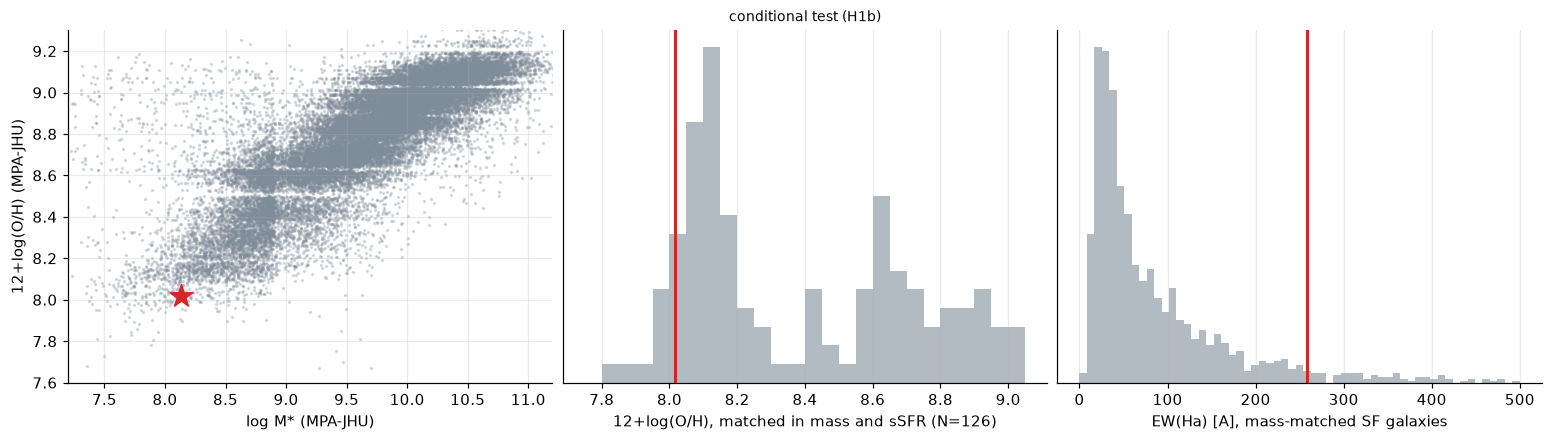

In [9]:
# --- H1a: position on the MPA-JHU mass-metallicity relation
oh_t = float(E.oh_p50)
win = g[g.lgm_tot_p50.between(lm - 0.15, lm + 0.15)]
R["H1_mzr_pct"] = pct(win.oh_p50, oh_t)
print(f"H1a  MZR: control within +-0.15 dex of log M*={lm:.2f}: N={len(win)}, median 12+log(O/H)={win.oh_p50.median():.2f}, "
      f"16-84%: {win.oh_p50.quantile(.16):.2f}..{win.oh_p50.quantile(.84):.2f}; target {oh_t:.2f} = {oh_t - win.oh_p50.median():+.2f} dex, "
      f"percentile {100 * R['H1_mzr_pct']:.1f}")

print(f"     the O/H estimator has a sharp lower edge at this mass: 1st/5th/10th percentile = "
      f"{win.oh_p50.quantile(.01):.2f}/{win.oh_p50.quantile(.05):.2f}/{win.oh_p50.quantile(.10):.2f}, so a deficit of 0.2 dex is already near the floor")

# --- H1b: still low *given* the burst strength?  Matched in mass AND sSFR. (A linear fit was tried first and rejected:
#     the O/H distribution is strongly skewed, so a mean-based fit overstated the deficit, and its sSFR coefficient was ~0.)
ss_t = float(E.specsfr_tot_p50)
bm = g[g.lgm_tot_p50.between(lm - 0.2, lm + 0.2)]
rho, pval = spearmanr(bm.oh_p50, bm.specsfr_tot_p50)
print(f"H1b  at fixed mass (+-0.2 dex, N={len(bm)}) O/H vs sSFR Spearman rho = {rho:+.2f} (p={pval:.3f}): a weak anti-correlation, as a mass-SFR-metallicity relation predicts")
rows = []
for dm, ds in [(0.15, 0.3), (0.20, 0.3), (0.25, 0.4), (0.30, 0.5)]:
    b = g[g.lgm_tot_p50.between(lm - dm, lm + dm) & g.specsfr_tot_p50.between(ss_t - ds, ss_t + ds)]
    rows.append({"mass bin +-": dm, "sSFR bin +-": ds, "N": len(b), "median O/H": b.oh_p50.median(),
                 "16-84%": f"{b.oh_p50.quantile(.16):.2f}..{b.oh_p50.quantile(.84):.2f}", "target percentile": 100 * pct(b.oh_p50, oh_t)})
cond = pd.DataFrame(rows); display(cond.round(2))
bmatch = g[g.lgm_tot_p50.between(lm - 0.2, lm + 0.2) & g.specsfr_tot_p50.between(ss_t - 0.3, ss_t + 0.3)]
R["H1_cond_pct"] = pct(bmatch.oh_p50, oh_t)
R["H1_cond_range"] = (cond["target percentile"].min(), cond["target percentile"].max())

# The matched control is bimodal (a main peak near 8.1-8.2 and a second one at 8.6-9.0, probably an estimator effect at low S/N).
# Robustness: compare only with the main low-metallicity peak.
main = bmatch[bmatch.oh_p50 < 8.45]
R["H1_main_pct"] = pct(main.oh_p50, oh_t)
print(f"main low-Z peak only (O/H<8.45): N={len(main)}, median {main.oh_p50.median():.2f}, 16-84%: {main.oh_p50.quantile(.16):.2f}..{main.oh_p50.quantile(.84):.2f}; "
      f"target {oh_t:.2f} is {oh_t - main.oh_p50.median():+.2f} dex from it, percentile {100 * R['H1_main_pct']:.1f}")

# --- H2: burst strength
ew_t = -float(L.h_alpha_eqw)
wm = g[g.lgm_tot_p50.between(lm - 0.3, lm + 0.3)]
R["H2_ew_pct"] = pct(-wm.h_alpha_eqw, ew_t); R["H2_ssfr_pct"] = pct(wm.specsfr_tot_p50, float(E.specsfr_tot_p50))
print(f"H2   EW(Ha)={ew_t:.0f} A: percentile {100 * R['H2_ew_pct']:.1f} among N={len(wm)} mass-matched SF galaxies (median {(-wm.h_alpha_eqw).median():.0f} A); "
      f"log sSFR={float(E.specsfr_tot_p50):.2f}: percentile {100 * R['H2_ssfr_pct']:.1f} (median {wm.specsfr_tot_p50.median():.2f})")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.9), constrained_layout=True)
ax[0].scatter(g.lgm_tot_p50, g.oh_p50, s=1.5, color=C_CTRL, alpha=0.25, rasterized=True)
ax[0].scatter([lm], [oh_t], marker="*", s=240, color=C_T, zorder=5)
ax[0].set_xlim(7.2, 11.2); ax[0].set_ylim(7.6, 9.3); ax[0].set_xlabel("log M* (MPA-JHU)"); ax[0].set_ylabel("12+log(O/H) (MPA-JHU)")
ax[1].hist(bmatch.oh_p50, bins=np.arange(7.75, 9.1, 0.05), color=C_CTRL, alpha=0.6); ax[1].axvline(oh_t, color=C_T, lw=2)
ax[1].set_xlabel(f"12+log(O/H), matched in mass and sSFR (N={len(bmatch)})"); ax[1].set_yticks([]); ax[1].set_title("conditional test (H1b)", fontsize=9)
ax[2].hist(-wm.h_alpha_eqw, bins=np.linspace(0, 500, 60), color=C_CTRL, alpha=0.6); ax[2].axvline(ew_t, color=C_T, lw=2)
ax[2].set_xlabel("EW(Ha) [A], mass-matched SF galaxies"); ax[2].set_yticks([])
plt.show()

**Reading.**

**H1a.** Against MPA-JHU star-forming galaxies within $\pm 0.15$ dex in mass, the target is 0.21 dex below the median (4.1th percentile): *weak*. Three details undercut even that:
1. The MPA-JHU O/H estimator has a sharp lower edge at this mass (5th percentile 8.03, target 8.02), so a 0.2 dex deficit is already near the floor.
2. Conditioning on sSFR as well leaves the target at the 5.9-7.1th percentile for all four bin choices, and the O/H-sSFR correlation at fixed mass is weak ($\rho = -0.09$). (I first tried a linear regression and rejected it: the O/H distribution is skewed, so it overstated the deficit.)
3. The matched control is **bimodal** (a main peak near 8.1-8.2 and a second one at 8.6-9.0, probably an estimator effect at low S/N). Against the main peak the target is only 0.09 dex low, at the 12.7th percentile.

With the direct-T$_e$ comparison from Section 5 (22nd percentile), there is **no robust metallicity deficit**. The object is on the low side of normal for its mass, and that is all the data support.

**H2.** EW(H$\alpha$) = 259 Å is the 94.7th percentile and log sSFR = $-8.46$ the 95.2nd among mass-matched galaxies (about 1 dex above the median sSFR). It is a starburst, but the control contains many galaxies up to 500 Å, so it is not extreme: *weak*. I did not fit a burst-age model; EW alone gives an age only through a population-synthesis model and assumptions about nebular continuum.

## 7. Neutral hydrogen (H4)

ALFALFA (Haynes et al. 2018) lists this galaxy as AGC 227547. The comparison sample is every ALFALFA source in a 35° x 20° box around it whose optical counterpart matches an SDSS galaxy within 3″ and 300 km/s, with MPA-JHU stellar masses, so depth and mass estimator match the target's.

,AGC,Vhel,W50,HIflux,e_HIflux,SNR,Dist,logMHI,e_logMHI,HI code
0,227547,10008,94,0.7,0.09,5.0,146.5,9.55,0.07,2


ALFALFA sources within 10 arcmin of the target (incl. itself): 1
HI-optical velocity: Vhel=10008 km/s vs SDSS cz=10007 km/s;  beam ~3.8 arcmin = 157 kpc;  W50=94 km/s
HI code 2 = lower-significance detection accepted because an optical counterpart at the right redshift exists (see Haynes+18); S/N = 5.0.


matched ALFALFA x SDSS control: N=2424
g-r=-0.11, M_r=-18.18, W1-W2=0.23


,log M*,log MHI/M*,control N (own-mass bin),control median,control 16-84%,percentile
mass estimate,,,,,,
MPA-JHU SED fit,8.13,1.42,167,0.87,0.49..1.12,97.60
colour (g-r) M/L,8.60,0.95,496,0.70,0.41..0.94,85.28
WISE W1 M/L=0.2,8.50,1.05,436,0.73,0.46..0.98,90.14
WISE W1 M/L=0.5,8.90,0.65,614,0.52,0.24..0.79,67.92


Caveat: the control masses are all MPA-JHU SED masses, so rows other than the first compare across mass scales; read them as a bracket, not a measurement.


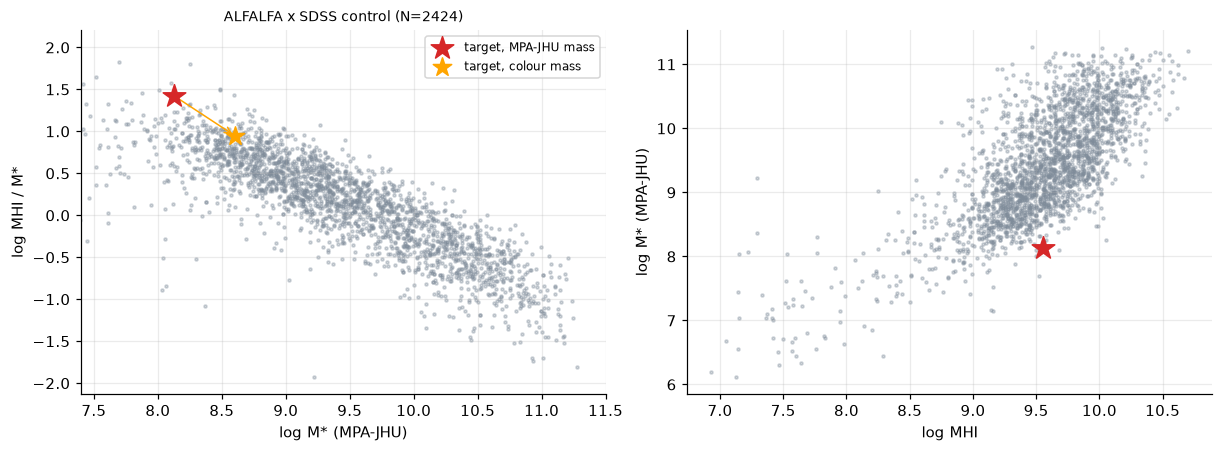

In [10]:
alf_row, alf_near = dd.alfalfa()
a1 = alf_row.iloc[0]
display(alf_row[["AGC", "Vhel", "W50", "HIflux", "e_HIflux", "SNR", "Dist", "logMHI", "e_logMHI", "HI"]].rename(columns={"HI": "HI code"}))
print(f"ALFALFA sources within 10 arcmin of the target (incl. itself): {len(alf_near)}")
print(f"HI-optical velocity: Vhel={a1.Vhel} km/s vs SDSS cz={z * 299792.458:.0f} km/s;  beam ~3.8 arcmin = {3.8 * 60 * KPC_PER_ARCSEC:.0f} kpc;  W50={a1.W50} km/s")
print("HI code 2 = lower-significance detection accepted because an optical counterpart at the right redshift exists (see Haynes+18); S/N = 5.0.")

hi, sd = dd.hi_control()
hi = hi.dropna(subset=["RAO", "DEO"]).copy()
co = SkyCoord(hi.RAO.values, hi.DEO.values, unit=(u.hourangle, u.deg))
cs = SkyCoord(sd.ra.values * u.deg, sd.dec.values * u.deg)
idx, sep, _ = co.match_to_catalog_sky(cs)
hi["sep"] = sep.arcsec
for col in ["specObjID", "z", "lgm_tot_p50", "bptclass"]:
    hi[col] = sd.iloc[idx][col].values
hi["dv"] = (hi.z * 299792.458 - hi.Vhel).abs()
hi = hi[(hi.sep < 3.0) & (hi.dv < 300) & (hi.specObjID != T["specObjID"])].copy()
hi["gasratio"] = hi.logMHI - hi.lgm_tot_p50
print(f"matched ALFALFA x SDSS control: N={len(hi)}")

# --- stellar-mass systematics: three independent estimates
gr = (P.modelMag_g - P.extinction_g) - (P.modelMag_r - P.extinction_r)
Mr = (P.modelMag_r - P.extinction_r) - 5 * np.log10(a1.Dist * 1e6 / 10)
logLr = -0.4 * (Mr - 4.65)
lm_colour = logLr + (-0.306 + 1.097 * gr) - 0.10          # Bell+03 g-r (diet Salpeter), -0.10 dex to Kroupa-like (approximate)
w = alf_row.iloc[0]
wise = dd.allwise().iloc[0]
MW1 = wise.W1mag - 5 * np.log10(a1.Dist * 1e6 / 10)       # Vega absolute mag
logLW1 = -0.4 * (MW1 - 3.24)                               # M_sun(W1,Vega) ~ 3.24 (assumed)
lm_w1 = (logLW1 + np.log10(0.2), logLW1 + np.log10(0.5))   # assumed M/L_W1 range 0.2-0.5
masses = {"MPA-JHU SED fit": lm, "colour (g-r) M/L": lm_colour, "WISE W1 M/L=0.2": lm_w1[0], "WISE W1 M/L=0.5": lm_w1[1]}
print(f"g-r={gr:.2f}, M_r={Mr:.2f}, W1-W2={wise.W1mag - wise.W2mag:.2f}")
mt = pd.DataFrame({"log M*": masses}); mt["log MHI/M*"] = a1.logMHI - mt["log M*"]
rows = []
for k, v in masses.items():
    b = hi[hi.lgm_tot_p50.between(v - 0.3, v + 0.3)]
    rows.append({"mass estimate": k, "log M*": v, "log MHI/M*": a1.logMHI - v, "control N (own-mass bin)": len(b),
                 "control median": b.gasratio.median(), "control 16-84%": f"{b.gasratio.quantile(.16):.2f}..{b.gasratio.quantile(.84):.2f}",
                 "percentile": 100 * pct(b.gasratio, a1.logMHI - v)})
hit = pd.DataFrame(rows).set_index("mass estimate")
display(hit.round(2))
print("Caveat: the control masses are all MPA-JHU SED masses, so rows other than the first compare across mass scales; read them as a bracket, not a measurement.")
R["H4_pct_mpa"], R["H4_pct_colour"] = hit.iloc[0]["percentile"] / 100, hit.iloc[1]["percentile"] / 100
R["H4_ratio_mpa"], R["H4_ratio_colour"] = hit.iloc[0]["log MHI/M*"], hit.iloc[1]["log MHI/M*"]

fig, ax = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
ax[0].scatter(hi.lgm_tot_p50, hi.gasratio, s=4, color=C_CTRL, alpha=0.35)
ax[0].scatter([lm], [a1.logMHI - lm], marker="*", s=240, color=C_T, zorder=5, label="target, MPA-JHU mass")
ax[0].scatter([lm_colour], [a1.logMHI - lm_colour], marker="*", s=160, color="orange", zorder=5, label="target, colour mass")
ax[0].annotate("", (lm_colour, a1.logMHI - lm_colour), (lm, a1.logMHI - lm), arrowprops=dict(arrowstyle="->", color="orange"))
ax[0].set_xlabel("log M* (MPA-JHU)"); ax[0].set_ylabel("log MHI / M*"); ax[0].legend(fontsize=8); ax[0].set_xlim(7.4, 11.5)
ax[0].set_title(f"ALFALFA x SDSS control (N={len(hi)})", fontsize=9)
ax[1].scatter(hi.logMHI, hi.lgm_tot_p50, s=4, color=C_CTRL, alpha=0.35)
ax[1].scatter([a1.logMHI], [lm], marker="*", s=240, color=C_T, zorder=5); ax[1].set_xlabel("log MHI"); ax[1].set_ylabel("log M* (MPA-JHU)")
plt.show()

### 7b. Is the gas-richness a selection effect?

An H I detection at 146 Mpc is only possible for a gas-rich dwarf, so a high gas ratio is partly what the detection *selects for*. Two checks: (i) what S/N this galaxy would have had at a typical gas ratio, and (ii) what gas ratios ALFALFA actually detects in dwarfs of this mass at different distances.

In [11]:
hi_all = dd.vizier("J/ApJ/861/49/table2", "alfalfa_box")                      # every ALFALFA source in the box, no SDSS match needed
ratio_t = a1.logMHI - lm
typ = hi[hi.lgm_tot_p50.between(lm - 0.3, lm + 0.3)].gasratio.median()
snr_typ = a1.SNR * 10 ** (typ - ratio_t)          # at fixed distance and line width the S/N scales linearly with H I flux
frac_below = float((hi_all.SNR <= snr_typ).mean())
print(f"Target: S/N={a1.SNR}, rms={a1.rms} mJy, log MHI/M*={ratio_t:.2f} (MPA-JHU mass).")
print(f"Had it carried the typical control ratio ({typ:.2f}), its S/N would be ~{snr_typ:.1f}; only {100 * frac_below:.1f}% of the {len(hi_all)} ALFALFA catalogue entries in this box have S/N that low.")

rows = []
for lo, hi_d in [(0, 60), (60, 100), (100, 130), (130, 1000)]:
    b = hi[(hi.Dist >= lo) & (hi.Dist < hi_d) & hi.lgm_tot_p50.between(lm - 0.4, lm + 0.4)]
    rows.append({"distance [Mpc]": f"{lo}-{hi_d}" if hi_d < 1000 else f"{lo}+", "N detected dwarfs (M* +-0.4 dex)": len(b),
                 "median log MHI/M*": b.gasratio.median() if len(b) else np.nan,
                 "minimum": b.gasratio.min() if len(b) else np.nan, "minimum log MHI": b.logMHI.min() if len(b) else np.nan})
det = pd.DataFrame(rows).set_index("distance [Mpc]"); display(det.round(2))
far = hi[(hi.Dist >= 130) & hi.lgm_tot_p50.between(lm - 0.4, lm + 0.4)]
R["H4_snr_typ"], R["H4_frac_below"], R["H4_far_n"] = snr_typ, frac_below, len(far)
R["H4_far_range"] = (far.gasratio.min(), far.gasratio.max()) if len(far) else (np.nan, np.nan)
print(f"Detected dwarfs of this mass beyond 130 Mpc: N={len(far)}, gas ratios {R['H4_far_range'][0]:.2f}..{R['H4_far_range'][1]:.2f}; target {ratio_t:.2f}. "
      "The detected gas ratio rises with distance: the flux limit, not the galaxies, sets the floor.")

Target: S/N=5.0, rms=3.19 mJy, log MHI/M*=1.42 (MPA-JHU mass).
Had it carried the typical control ratio (0.87), its S/N would be ~1.4; only 0.0% of the 3566 ALFALFA catalogue entries in this box have S/N that low.


,N detected dwarfs (M* +-0.4 dex),median log MHI/M*,minimum,minimum log MHI
distance [Mpc],,,,
0-60,77,0.62,-1.08,7.15
60-100,103,0.81,0.20,8.49
100-130,79,0.90,0.28,8.80
130+,3,1.51,1.22,9.45


Detected dwarfs of this mass beyond 130 Mpc: N=3, gas ratios 1.22..1.80; target 1.42. The detected gas ratio rises with distance: the flux limit, not the galaxies, sets the floor.


**Reading.**

ALFALFA lists AGC 227547 at the right velocity (10008 vs 10007 km/s) with $\log M_\mathrm{HI} = 9.55 \pm 0.07$ and W50 = 94 km/s, but as a **code-2, S/N = 5.0** detection (accepted because an optical counterpart exists). With the MPA-JHU stellar mass the gas ratio $\log M_\mathrm{HI}/M_\star = 1.42$ is the 97.6th percentile of ALFALFA-detected galaxies of that mass. Two systematics matter more than that percentile:

- **Stellar mass.** Three independent estimates (SED fit 8.13; $g-r$ colour 8.60; W1 luminosity with an assumed M/L of 0.2-0.5, giving 8.50-8.90) span 0.8 dex, and the gas ratio runs from 1.42 down to 0.65. Under the colour mass the target is at the 85th percentile. Starbursts are hard cases: emission lines contaminate the broad bands (H$\alpha$ in $r$, [O III] in $g$) and young populations make colour-based M/L ambiguous. I cannot say which estimate is right. (The Bell et al. coefficients and the W1 M/L range are from memory or assumed, and the other rows compare across mass scales, so read them as a bracket.)
- **Detection limit (7b).** At 146.5 Mpc the galaxy is detected at S/N = 5.0. Had it carried the typical gas ratio for its mass (0.87), its S/N would be about 1.4, below every entry among the 3566 catalogue sources in this box. The median *detected* ratio for dwarfs of this mass rises with distance (0.62, 0.81, 0.90, then 1.5 beyond 130 Mpc), and only three such dwarfs are detected beyond 130 Mpc, with ratios 1.22-1.80. A high ratio is therefore what a detection *here* selects for. This one measurement cannot distinguish "unusually gas-rich dwarf" from "one of many typical dwarfs at this distance that was gas-rich enough to detect". **H4: selection-limited**, not anomalous. (Three galaxies is a small number, so this is an argument from the selection mechanism more than from the table.)

## 8. Multiwavelength picture and environment (H5, context)

,u,g,r,i,z
"AB mag (model, extinction-corrected)",18.221,17.542,17.653,17.607,17.637
error,0.020,0.005,0.007,0.009,0.032


colours: u-g=0.68  g-r=-0.11  r-i=0.05;  M_r=-18.18;  petroR50_r=2.0 arcsec = 1.4 kpc;  fibre light fraction in mass: 0.28 (MPA-JHU)


,AllWISE,W1mag,e_W1mag,W2mag,e_W2mag,W3mag,e_W3mag,W4mag,e_W4mag
AllWISE,J125116.64+350648.3,16.065,0.056,15.835,0.127,12.399,NaN,8.652,0.382


W1-W2 = 0.23 (mid-IR AGN selections need W1-W2 >~ 0.8: Stern+12); W3 has no error (upper limit); W4 S/N = 2.8.
GALEX GUVcat_AIS entries within 15 arcsec: 0 (none found; coverage of this field was not verified)


,specObjID,sep_kpc,dv_kms,M_r,class,subClass
0,2237308313597405184,185.6,1509.1,-21.4,GALAXY,NaN
1,2237306939207870464,245.8,1541.9,-19.0,GALAXY,NaN
2,2286780290925881344,419.6,-62.9,-20.8,GALAXY,AGN
3,2276573524132915200,740.6,-179.5,-20.3,GALAXY,STARBURST
4,2237308863353219072,755.0,-187.0,-18.4,GALAXY,STARFORMING
5,2276573799010822144,760.2,-353.8,-19.8,GALAXY,STARFORMING
6,2237310787498567680,793.8,-393.4,-19.5,GALAXY,STARFORMING
7,2276574348766636032,824.9,-371.2,-18.4,GALAXY,STARBURST


neighbours within 600 kpc and +-500 km/s: 1; the nearest is 420 kpc away, dv=-63 km/s, 11x more luminous in r, subclass AGN
SDSS-spectroscopic galaxies inside the ALFALFA beam (radius 1.9 arcmin, any velocity within +-2000 km/s): 0. Dwarfs without SDSS spectra could still be inside the beam; this check cannot exclude them.


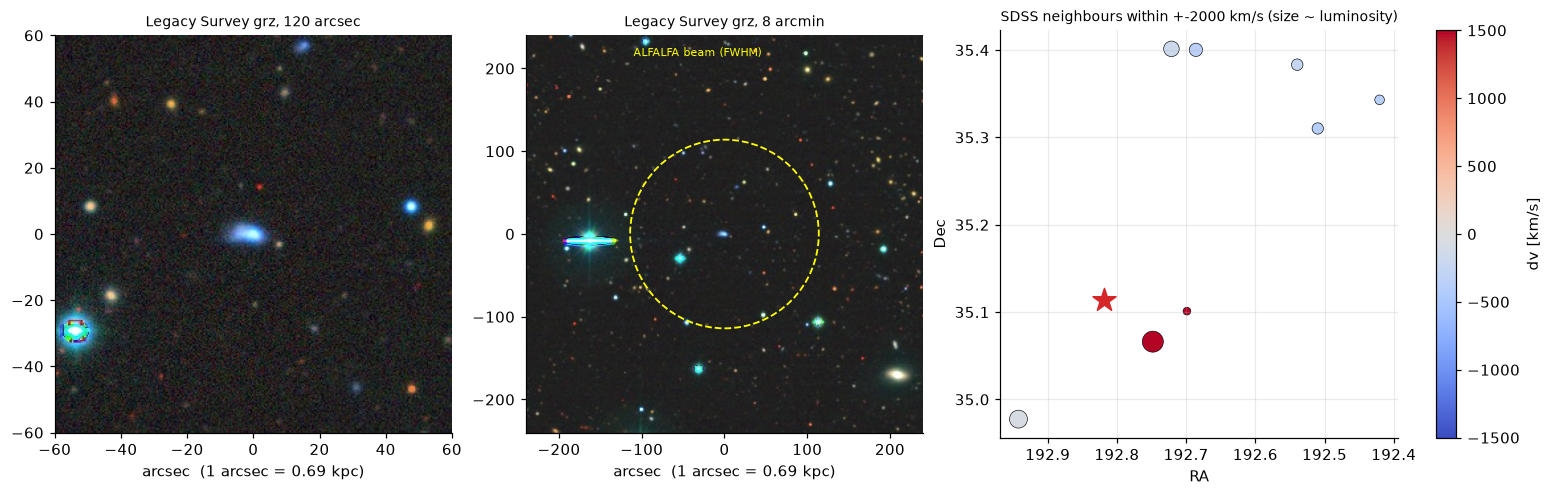

In [12]:
phot = pd.DataFrame({"AB mag (model, extinction-corrected)": {b: P[f"modelMag_{b}"] - P[f"extinction_{b}"] for b in "ugriz"}})
phot["error"] = [P[f"modelMagErr_{b}"] for b in "ugriz"]
display(phot.round(3).T)
print(f"colours: u-g={phot.iloc[0, 0] - phot.iloc[1, 0]:.2f}  g-r={gr:.2f}  r-i={phot.iloc[2, 0] - phot.iloc[3, 0]:.2f};  M_r={Mr:.2f};  petroR50_r={P.petroR50_r:.1f} arcsec = {P.petroR50_r * KPC_PER_ARCSEC:.1f} kpc;  "
      f"fibre light fraction in mass: {10 ** (E.lgm_fib_p50 - E.lgm_tot_p50):.2f} (MPA-JHU)")
wdisp = wise[["AllWISE", "W1mag", "e_W1mag", "W2mag", "e_W2mag", "W3mag", "e_W3mag", "W4mag", "e_W4mag"]]
display(wdisp.to_frame("AllWISE").T)
w12 = wise.W1mag - wise.W2mag
print(f"W1-W2 = {w12:.2f} (mid-IR AGN selections need W1-W2 >~ 0.8: Stern+12); W3 has no error (upper limit); W4 S/N = {1.086 / wise.e_W4mag:.1f}.")
gx = dd.galex()
print("GALEX GUVcat_AIS entries within 15 arcsec:", len(gx), "(none found; coverage of this field was not verified)" if len(gx) == 0 else "")
R["W1W2"] = w12

# ---- environment: spectroscopic neighbours within +-2000 km/s
nb = dd.spec_neighbours()
cn = SkyCoord(nb.ra.values * u.deg, nb.dec.values * u.deg); ct = SkyCoord(T["ra"] * u.deg, T["dec"] * u.deg)
nb["sep_kpc"] = ct.separation(cn).arcmin * KPC_PER_ARCSEC * 60
nb["dv_kms"] = (nb.z - z) * 299792.458 / (1 + z)
nb["M_r"] = nb.modelMag_r - cosmo.distmod(nb.z).value
nb = nb[nb.specObjID != T["specObjID"]].sort_values("sep_kpc")
display(nb[["specObjID", "sep_kpc", "dv_kms", "M_r", "class", "subClass"]].round(1).head(8).reset_index(drop=True))
close = nb[(nb.sep_kpc < 600) & (nb.dv_kms.abs() < 500)]
print(f"neighbours within 600 kpc and +-500 km/s: {len(close)}"
      + (f"; the nearest is {close.iloc[0].sep_kpc:.0f} kpc away, dv={close.iloc[0].dv_kms:+.0f} km/s, {10 ** (-0.4 * (close.iloc[0].M_r - (Mr))):.0f}x more luminous in r, subclass {close.iloc[0].subClass}" if len(close) else ""))
R["n_close"] = len(close)
in_beam = nb[nb.sep_kpc / KPC_PER_ARCSEC / 60 < 3.8 / 2]
print(f"SDSS-spectroscopic galaxies inside the ALFALFA beam (radius 1.9 arcmin, any velocity within +-2000 km/s): {len(in_beam)}. "
      "Dwarfs without SDSS spectra could still be inside the beam; this check cannot exclude them.")
R["n_in_beam"] = len(in_beam)

fig, ax = plt.subplots(1, 3, figsize=(14, 4.4), constrained_layout=True)
for a_, f_, ttl, sz in [(ax[0], "legacy_120arcsec", "Legacy Survey grz, 120 arcsec", 120), (ax[1], "legacy_8arcmin", "Legacy Survey grz, 8 arcmin", 480)]:
    a_.imshow(plt.imread(dd._path(f_ + ".jpg")), extent=[-sz / 2, sz / 2, -sz / 2, sz / 2]); a_.set_title(ttl, fontsize=9); a_.grid(False)
    a_.set_xlabel(f"arcsec  (1 arcsec = {KPC_PER_ARCSEC:.2f} kpc)")
ax[1].add_patch(plt.Circle((0, 0), 3.8 * 60 / 2, fill=False, ec="yellow", lw=1.2, ls="--")); ax[1].annotate("ALFALFA beam (FWHM)", (-110, 215), color="yellow", fontsize=7)
sc_ = ax[2].scatter(nb.ra, nb.dec, c=nb.dv_kms, cmap="coolwarm", vmin=-1500, vmax=1500, s=20 * 10 ** (-0.4 * (nb.M_r + 19)) ** 0.5, edgecolor="k", lw=0.4)
ax[2].scatter([T["ra"]], [T["dec"]], marker="*", s=250, color=C_T, zorder=5); ax[2].invert_xaxis()
ax[2].set_xlabel("RA"); ax[2].set_ylabel("Dec"); ax[2].set_title("SDSS neighbours within +-2000 km/s (size ~ luminosity)", fontsize=9)
fig.colorbar(sc_, ax=ax[2], label="dv [km/s]")
plt.show()

**Reading.**

- **Photometry.** Compact and blue: $g-r = -0.11$, $M_r = -18.2$, $r_{50} = 2.0'' = 1.4$ kpc. MPA-JHU puts 28% of the stellar mass inside the 2.1 kpc fibre, so the spectrum samples the central region, not the whole galaxy.
- **No AGN evidence (H5).** AllWISE gives $W1-W2 = 0.23$, far below the ~0.8 mid-IR AGN threshold (Stern et al. 2012). W3 is an upper limit and W4 is only a 2.8$\sigma$ detection, so I draw no conclusion from the long-wavelength bands. GALEX has no entry in GUVcat_AIS (I did not verify whether the field was observed).
- **Environment.** The only SDSS galaxy within 600 kpc and $\pm 500$ km/s is an AGN-classified galaxy 420 kpc away at $\Delta v = -63$ km/s, 11$\times$ more luminous in $r$. Two brighter galaxies at 186 and 246 kpc have $\Delta v \approx +1500$ km/s and are probably a different structure. Several star-forming galaxies lie at 740-880 kpc with $\Delta v$ from $-180$ to $-390$ km/s. The dwarf is therefore not isolated. Tidal triggering or accretion from a group environment is possible but **untested here, and I make no claim about it.**
- **H I confusion.** No SDSS-spectroscopic galaxy lies inside the ALFALFA beam, and ALFALFA lists no other H I source within 10 arcmin. Dwarfs without SDSS spectra could still be in the beam, so this lowers but does not remove the confusion risk.

## 9. Literature

In [13]:
bib = ["2000A&AS..142..417H", "2018ApJ...861...49H", "2022ApJS..261...21Y", "2023ApJS..269....3M", "2003AJ....126.2152R", "2015A&A...578A.110A"]
refs = dd.simbad_references(bib).set_index("bibcode").loc[bib]
role = {"2000A&AS..142..417H": "survey list that includes the object as HS 1248+3523 (emission-line galaxy)",
        "2018ApJ...861...49H": "ALFALFA H I catalogue: source of the H I mass used in section 7",
        "2022ApJS..261...21Y": "H I profile-shape statistics for nearby galaxies (catalogue-level)",
        "2023ApJS..269....3M": "Siena Galaxy Atlas (imaging catalogue)",
        "2003AJ....126.2152R": "CAIRNS cluster survey redshifts (catalogue-level)",
        "2015A&A...578A.110A": "catalogues of isolated galaxies/pairs/triplets (membership not verified here)"}
refs["role"] = pd.Series(role)
pd.set_option("display.max_colwidth", 95); pd.set_option("display.width", 220)
display(refs[["year", "title", "doi", "role"]])
print("By SIMBAD's record, none of the six papers is a dedicated study of this object: all are survey or catalogue papers.")

,year,title,doi,role
bibcode,,,,
2000A&AS..142..417H,2000,The Hamburg/SAO survey for emission-line galaxies. III. The third list of 81 galaxies.,10.1051/aas:2000162,survey list that includes the object as HS 1248+3523 (emission-line galaxy)
2018ApJ...861...49H,2018,The Arecibo Legacy Fast ALFA survey: the ALFALFA extragalactic H I source catalog.,10.3847/1538-4357/aac956,ALFALFA H I catalogue: source of the H I mass used in section 7
2022ApJS..261...21Y,2022,Statistical Analysis of H I Profile Asymmetry and Shape for Nearby Galaxies.,10.3847/1538-4365/ac626b,H I profile-shape statistics for nearby galaxies (catalogue-level)
2023ApJS..269....3M,2023,Siena Galaxy Atlas 2020.,10.3847/1538-4365/acfaa2,Siena Galaxy Atlas (imaging catalogue)
2003AJ....126.2152R,2003,CAIRNS: the cluster and infall region nearby survey. I. Redshifts and mass profiles.,10.1086/378599,CAIRNS cluster survey redshifts (catalogue-level)
2015A&A...578A.110A,2015,"Catalogues of isolated galaxies, isolated pairs, and isolated triplets in the local Universe.",10.1051/0004-6361/201526016,catalogues of isolated galaxies/pairs/triplets (membership not verified here)


By SIMBAD's record, none of the six papers is a dedicated study of this object: all are survey or catalogue papers.


In [14]:
QUERIES = {
 "tremonti04": "Tremonti 2004 The origin of the mass-metallicity relation: insights from 53,000 star-forming galaxies in the SDSS",
 "brinchmann04": "Brinchmann 2004 The physical properties of star-forming galaxies in the low-redshift universe",
 "izotov06": "Izotov Stasinska Meynet Guseva Thuan 2006 chemical composition of metal-poor emission-line galaxies in the Data Release 3 of the Sloan Digital Sky Survey",
 "izotov_thuan99": "Izotov Thuan 1999 Heavy-element abundances in blue compact galaxies",
 "kunth_ostlin00": "Kunth Ostlin 2000 The most metal-poor galaxies",
 "kewley_ellison08": "Kewley Ellison 2008 Metallicity calibrations and the mass-metallicity relation for star-forming galaxies",
 "pettini_pagel04": "Pettini Pagel 2004 [OIII]/[NII] as an abundance indicator at high redshift",
 "mannucci10": "Mannucci 2010 A fundamental relation between mass, star formation rate and metallicity in local and high-redshift galaxies",
 "sanchez_almeida14": "Sanchez Almeida Elmegreen Munoz-Tunon Elmegreen 2014 Star formation in the local universe: metal-poor gas accretion Astronomy and Astrophysics Review",
 "bell03": "Bell McIntosh Katz Weinberg 2003 The optical and near-infrared properties of galaxies. I. Luminosity and stellar mass functions",
 "huang12": "Huang Haynes Giovanelli 2012 The Arecibo Legacy Fast ALFA Survey: the galaxy population detected by ALFALFA",
 "stern12": "Stern 2012 Mid-infrared selection of active galaxies with the Wide-field Infrared Survey Explorer I. Characterizing WISE-selected active galactic nuclei in COSMOS",
 "asplund09": "Asplund Grevesse Sauval Scott 2009 The Chemical Composition of the Sun Annual Review of Astronomy and Astrophysics 47 481",
}
used = {"tremonti04": "mass-metallicity relation; MPA-JHU context", "brinchmann04": "MPA-JHU measurements used throughout",
        "izotov06": "direct-Te equations (section 5); I wrote the coefficients from memory and validated them on 807 galaxies",
        "izotov_thuan99": "N/O plateau in metal-poor galaxies (H3)", "kunth_ostlin00": "review of the most metal-poor galaxies (H1 context)",
        "kewley_ellison08": "why direct-Te and model/strong-line O/H differ by a few tenths of a dex",
        "pettini_pagel04": "N2/O3N2 strong-line calibrations", "mannucci10": "mass-SFR-metallicity relation (basis of the conditional test, H1b)",
        "sanchez_almeida14": "metal-poor gas accretion feeding star formation (interpretation of H1+H2+H4 together)",
        "bell03": "colour-based stellar mass (section 7); coefficients from memory", "huang12": "ALFALFA gas fractions of SDSS galaxies (H4 context)",
        "stern12": "W1-W2 >= 0.8 mid-IR AGN criterion (H5)", "asplund09": "solar oxygen abundance 8.69"}
cr = dd.crossref_lookup(QUERIES).set_index("key")
cr["used for"] = pd.Series(used)
display(cr[["first_author", "year", "journal", "doi", "title", "used for"]])
print("Crossref returns the best bibliographic match; each row above was read and judged to be the intended paper. I have not read these papers in full for this notebook; roles are limited to what the titles state.")

,first_author,year,journal,doi,title,used for
key,,,,,,
tremonti04,Tremonti,2004,The Astrophysical Journal,10.1086/423264,"The Origin of the Mass‐Metallicity Relation: Insights from 53,000 Star‐forming Galaxies in ...",mass-metallicity relation; MPA-JHU context
brinchmann04,Brinchmann,2004,Monthly Notices of the Royal Astronomical Society,10.1111/j.1365-2966.2004.07881.x,The physical properties of star-forming galaxies in the low-redshift Universe,MPA-JHU measurements used throughout
izotov06,Izotov,2006,Astronomy & Astrophysics,10.1051/0004-6361:20053763,The chemical composition of metal-poor emission-line galaxies in the Data Release 3 of the ...,direct-Te equations (section 5); I wrote the coefficients from memory and validated them on...
izotov_thuan99,Izotov,1999,The Astrophysical Journal,10.1086/306708,Heavy‐Element Abundances in Blue Compact Galaxies,N/O plateau in metal-poor galaxies (H3)
kunth_ostlin00,Kunth,2000,Astronomy and Astrophysics Review,10.1007/s001590000005,The most metal-poor galaxies,review of the most metal-poor galaxies (H1 context)
kewley_ellison08,Kewley,2008,The Astrophysical Journal,10.1086/587500,Metallicity Calibrations and the Mass‐Metallicity Relation for Star‐forming Galaxies,why direct-Te and model/strong-line O/H differ by a few tenths of a dex
pettini_pagel04,Pettini,2004,Monthly Notices of the Royal Astronomical Society,10.1111/j.1365-2966.2004.07591.x,[O iii]/[N ii] as an abundance indicator at high redshift,N2/O3N2 strong-line calibrations
mannucci10,Mannucci,2010,Monthly Notices of the Royal Astronomical Society,10.1111/j.1365-2966.2010.17291.x,"A fundamental relation between mass, star formation rate and metallicity in local and high-...","mass-SFR-metallicity relation (basis of the conditional test, H1b)"
sanchez_almeida14,Sánchez Almeida,2014,The Astronomy and Astrophysics Review,10.1007/s00159-014-0071-1,Star formation sustained by gas accretion,metal-poor gas accretion feeding star formation (interpretation of H1+H2+H4 together)


Crossref returns the best bibliographic match; each row above was read and judged to be the intended paper. I have not read these papers in full for this notebook; roles are limited to what the titles state.


**Reading.**

- **The object.** By SIMBAD's record **no paper is dedicated to this galaxy**. It enters the literature as HS 1248+3523 in the Hamburg/SAO emission-line galaxy survey (third list), as AGC 227547 in ALFALFA, and in large catalogue papers. SIMBAD also lists Argudo-Fernández et al. (2015), the catalogue of isolated galaxies, pairs and triplets, but I could not retrieve a row for this position, so any isolation or pair membership is **unresolved**, and my own neighbour census above is the only environment evidence. "No dedicated study" is limited to SIMBAD's list; I did not search NED or ADS full text.
- **The class.** The context papers (titles only; I have not read them in full for this notebook): direct-T$_e$ chemistry of SDSS metal-poor emission-line galaxies (Izotov et al. 2006), the mass-metallicity relation (Tremonti et al. 2004), the N/O behaviour of blue compact galaxies (Izotov & Thuan 1999), a review of the most metal-poor galaxies (Kunth & Östlin 2000), and a review titled "Star formation sustained by gas accretion" (Sánchez Almeida et al. 2014).
- **Interpretation.** A combination of lowish O/H, lowish N/O, a strong starburst and a high gas ratio is the kind of picture usually discussed in terms of metal-poor gas accretion. In my data each piece is marginal and the gas piece is selection-limited, so accretion is a hypothesis this notebook can neither support nor exclude.

## 10. Verdict

The table is generated from the numbers computed above by the decision rules in section 1.

In [15]:
def verdict(tail_p, strong=0.025, weak=0.10):
    return "supported" if tail_p <= strong else ("weak / suggestive" if tail_p <= weak else "not supported")

tail_nii = R["ctx_nii_pct_ctrl"] / 100
rows = [
 ("H0 context shift", "[N II]/Ha percentile: 10k sample -> mass-matched SF control", f"{R['ctx_nii_pct_10k']:.2f}th -> {R['ctx_nii_pct_ctrl']:.1f}th",
  "partly supported" if tail_nii <= 0.025 else "supported",
  f"extremeness shrinks ~100x with context, but a low end persists; vs same-O/H controls the offset is {R['N2_offset']:+.2f} dex "
  f"(N/O explains {R['N2_by_NO']:+.2f}, O/H {R['N2_by_OH']:+.2f})"),
 ("H1a metal-poor for its mass (MPA-JHU)", "O/H percentile at fixed M*", f"{100 * R['H1_mzr_pct']:.1f}th", verdict(R["H1_mzr_pct"]),
  "estimator has a sharp lower edge; deficit is only ~0.2 dex"),
 ("H1b ... and for its sSFR", "O/H percentile, matched in M* and sSFR", f"{100 * R['H1_cond_pct']:.1f}th (range {R['H1_cond_range'][0]:.1f}-{R['H1_cond_range'][1]:.1f} over bin choices)",
  verdict(R["H1_cond_pct"]), "conditioning on sSFR barely changes anything (rho = -0.09)"),
 ("H1b' ... main low-Z peak only", "O/H percentile vs the main peak (O/H<8.45)", f"{100 * R['H1_main_pct']:.1f}th", verdict(R["H1_main_pct"]),
  "control O/H is bimodal (estimator artefact?); against the main peak the deficit is small"),
 ("H1c ... direct-Te vs direct-Te controls", "O/H percentile among 4363-detected controls at the same M*", f"{100 * R['H1d_pct']:.1f}th ({R['H1d_dex']:+.2f} dex, N={R['H1d_n']})", verdict(R["H1d_pct"]),
  "same method on both sides, but controls are biased toward low O/H"),
 ("H1d extremely metal-poor (direct-Te)", "12+log(O/H) vs the 7.35 threshold", f"{R['OH_direct_own']:.2f} (own) / {R['OH_direct_mpa']:.2f} (MPA flux)",
  "not supported" if R["OH_direct_own"] > 7.35 else "supported", "0.18-0.19 Zsun: low-metallicity, not extreme"),
 ("H2 extreme burst", "EW(Ha) percentile at fixed M*", f"{100 * R['H2_ew_pct']:.1f}th", verdict(1 - R["H2_ew_pct"]),
  "sSFR percentile is similar; no age model fitted"),
 ("H3 low N/O", "log N/O vs controls at the same O/H", f"{R['H3_dex']:+.2f} dex, {100 * R['H3_pct']:.1f}th pct", verdict(R["H3_pct"]),
  "robust to [N II] S/N cut; absolute plateau comparison depends on remembered coefficients"),
 ("H4 gas-rich (MPA-JHU mass)", "log MHI/M* percentile", f"{R['H4_ratio_mpa']:.2f}, {100 * R['H4_pct_mpa']:.1f}th", "selection-limited",
  f"typical ratio would give S/N~{R['H4_snr_typ']:.1f}; far dwarfs detected only at {R['H4_far_range'][0]:.1f}-{R['H4_far_range'][1]:.1f}"),
 ("H4 gas-rich (colour mass)", "log MHI/M* percentile (bracket)", f"{R['H4_ratio_colour']:.2f}, {100 * R['H4_pct_colour']:.0f}th", verdict(1 - R["H4_pct_colour"]),
  "stellar mass is uncertain by ~0.5 dex"),
 ("H5 artefact / AGN contamination", "4363 S/N (own fit); W1-W2", f"S/N={R['snr_4363_own']:.1f}; W1-W2={R['W1W2']:.2f}",
  "not supported" if (R["snr_4363_own"] > 5 and R["W1W2"] < 0.8) else "check", "own fit agrees with MPA-JHU; no sky/mask contamination"),
]
vt = pd.DataFrame(rows, columns=["hypothesis", "metric", "value", "outcome", "caveat"]).set_index("hypothesis")
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 250)
display(vt)

,metric,value,outcome,caveat
hypothesis,,,,
H0 context shift,[N II]/Ha percentile: 10k sample -> mass-matched SF control,0.02th -> 2.1th,partly supported,"extremeness shrinks ~100x with context, but a low end persists; vs same-O/H controls t..."
H1a metal-poor for its mass (MPA-JHU),O/H percentile at fixed M*,4.1th,weak / suggestive,estimator has a sharp lower edge; deficit is only ~0.2 dex
H1b ... and for its sSFR,"O/H percentile, matched in M* and sSFR",7.1th (range 5.9-7.1 over bin choices),weak / suggestive,conditioning on sSFR barely changes anything (rho = -0.09)
H1b' ... main low-Z peak only,O/H percentile vs the main peak (O/H<8.45),12.7th,not supported,control O/H is bimodal (estimator artefact?); against the main peak the deficit is small
H1c ... direct-Te vs direct-Te controls,O/H percentile among 4363-detected controls at the same M*,"22.2th (-0.12 dex, N=99)",not supported,"same method on both sides, but controls are biased toward low O/H"
H1d extremely metal-poor (direct-Te),12+log(O/H) vs the 7.35 threshold,7.94 (own) / 7.97 (MPA flux),not supported,"0.18-0.19 Zsun: low-metallicity, not extreme"
H2 extreme burst,EW(Ha) percentile at fixed M*,94.7th,weak / suggestive,sSFR percentile is similar; no age model fitted
H3 low N/O,log N/O vs controls at the same O/H,"-0.24 dex, 2.9th pct",weak / suggestive,robust to [N II] S/N cut; absolute plateau comparison depends on remembered coefficients
H4 gas-rich (MPA-JHU mass),log MHI/M* percentile,"1.42, 97.6th",selection-limited,typical ratio would give S/N~1.4; far dwarfs detected only at 1.2-1.8


**Summary of the verdicts.**

- **Not supported or rejected:** extremely metal-poor (H1d), metallicity deficit against like-for-like controls (H1b', H1c), artefact or AGN (H5), gas-rich under the colour mass (H4).
- **Weak / suggestive (2.5% < p $\le$ 10%):** metal-poor for its mass in the MPA-JHU frame (H1a, H1b), strong burst (H2), low N/O (H3).
- **Selection-limited:** gas-richness under the MPA-JHU mass (H4).
- **H0 (context) is partly supported:** the extremeness shrinks about 100-fold once the comparison is made against mass-matched galaxies, and the residual low-$[\mathrm{N\,II}]/\mathrm{H}\alpha$ is mostly low N/O.

**No hypothesis reaches the 2.5% bar.** The closest is H3 at 2.9%, from about a dozen correlated comparisons, so I would not treat it as evidence. The most defensible statement is that **the detector recovered the tail of the dwarf-starburst population**: a real, well-measured, low-metallicity starburst dwarf whose apparent anomaly is mostly the sample's mass context, with a modest nitrogen deficit that deserves a second look.

**Limitations.** One object, so no population statement. Control sets are archival and carry their own selections (4363-detected controls favour hot, metal-poor gas; ALFALFA controls favour gas-rich dwarfs at distance). The MPA-JHU O/H estimator is bimodal at low mass. Coefficients for direct-T$_e$ N/O and the colour-based mass come from memory and were checked only indirectly. SIMBAD-only literature coverage.

## 11. Interpretation, and what to do next

*This section is an interpretation: a hypothesis built on the evidence above, not a finding. The numbers it relies on are all generated earlier in the notebook.*

### What I think is happening

Most likely this is an **ordinary gas-rich dwarf starburst**, and the one odd feature is a modest nitrogen deficit that may not survive scrutiny. Three observations fit a single picture:

- **A young burst.** EW(H$\alpha$) = 259 Å (95th percentile at this mass) and a compact size ($r_{50} = 1.4$ kpc) point to a burst a few Myr old that dominates the light of the central region.
- **Low N/O.** Oxygen comes quickly from massive stars; nitrogen comes mostly from intermediate-mass stars on a delay of hundreds of Myr. A galaxy with little star formation before this burst, or one whose oxygen has just been boosted by this burst, would show low N/O at a given O/H.
- **Gas to fuel it.** The H I (if the stellar mass and the S/N = 5 detection hold) is the reservoir, possibly gas with little prior processing.

Taken together: a dwarf that forms much of its stars late, caught early in a strong burst. That is a familiar kind of object, not an exotic one. If the N/O offset is real I lean toward this picture; if it is not, there is nothing unusual left to explain.

### What I do not think the data support

| Idea | Why not |
|---|---|
| An extremely metal-poor galaxy | direct-T$_e$ $12+\log(\mathrm{O/H}) = 7.94$, 0.6 dex above the 7.35 cut |
| A real metallicity deficit for its mass | 22nd percentile against direct-T$_e$ controls; 12.7th against the main peak of the MPA-JHU control |
| An AGN or an artefact | 4363 recovered independently at S/N 12.6; no sky or mask contamination; $W1-W2 = 0.23$ |
| Anomalous gas-richness | an H I detection at 146 Mpc selects for it (typical ratio $\Rightarrow$ S/N $\approx$ 1.4), and the stellar mass is uncertain by 0.5-0.8 dex |
| Strong tidal triggering | the only plausible companion is 420 kpc away; interaction signatures are usually seen at far smaller separations (general knowledge, not tested here) |

### What would confirm or refute it

Each row says what I would expect if my picture is right and what would count against it.

| # | Test | If my picture is right | If it is wrong | Cost |
|---|---|---|---|---|
| 1 | N/O residual vs EW(H$\alpha$) and sSFR in the 807 direct-T$_e$ controls, at fixed O/H | residual anticorrelates with burst strength | no trend: the burst-timing mechanism is unsupported | cheap, existing data, **not yet run** |
| 2 | Re-derive O/H and N/O with an atomic-physics code (for example PyNeb) and compare with a published direct-T$_e$ sample | the offset persists (about $-0.2$ dex) | the offset shrinks below about 0.1 dex: noise or my coefficients | cheap, needs a new dependency |
| 3 | Same matched-control analysis on candidate #6 | also low N/O | ordinary N/O: a one-off or chance | cheap, existing data |
| 4 | Older-population indicators from the existing spectrum (D4000, H$\delta$ absorption) | little older population | a substantial older population: "young burst only" fails | cheap, existing data |
| 5 | Deeper spectrum with [N II] $\lambda$5755 (auroral) | T$_e$([N II]) agrees with the adopted T$_e$([O II]); N/O stays low | T$_e$ differs: the N/O offset moves | new observation |
| 6 | IFU or long-slit spectroscopy | N/O low across the burst region | strong spatial variation: local enrichment, not a global property | new observation |
| 7 | He II 4686 and Wolf-Rayet features; UV imaging | burst age of a few Myr | older or more extended star formation | new observation |
| 8 | Deeper or resolved H I (GBT or VLA), plus near-IR stellar mass | the detection is confirmed and the gas ratio stays above about 1 under any mass | the detection fades, is confused, or the ratio is typical under the colour mass: the gas-rich claim drops | new observation |
| 9 | Deeper redshift coverage of faint neighbours | no close companion | a close dwarf companion: interaction becomes plausible | new observation |

**What would change my mind.** If tests 1 to 3 show no trend with burst strength, no offset in a proper atomic-physics code, and no repeat in candidate #6, I would call the low N/O noise and treat this object as a normal member of its population. If all three agree with the offset, it becomes the most interesting lead in this notebook and is worth observing.

### Next steps, in order

1. **Now, with existing data:** tests 1, 3 and 4.
2. **Needs a new dependency:** test 2 (an atomic-physics package such as PyNeb is not currently installed).
3. **If 1 to 3 hold up:** write the observing case, starting with tests 5 and 8.
4. **Independently of the outcome:** resolve the Argudo-Fernández et al. (2015) isolation or pair membership by finding the right VizieR table, and check the absolute N/O scale against a published sample.

### Reproducing this notebook

```
.venv/bin/python src/deep_dive_data.py        # fill the cache (needs network; ~1 min)
.venv/bin/pytest -q                            # unit tests for the physics code
.venv/bin/jupyter nbconvert --to notebook --execute notebooks/02_deep_dive_LEDA4572013.ipynb
```

### Data and software acknowledgements

- **SDSS-IV DR17** spectra and tables, and the **MPA-JHU** value-added catalogues (`galSpec*`), accessed through SkyServer and the SAS; the full SDSS acknowledgement is in the repository README.
- **ALFALFA** (Haynes et al. 2018), the **AllWISE** Data Release (Cutri et al. 2013) and the **GALEX** GUVcat (Bianchi et al. 2017), accessed through VizieR at CDS. This research has made use of the SIMBAD database and the VizieR catalogue access tool, CDS, Strasbourg, France.
- **DESI Legacy Imaging Surveys** cutouts from the Legacy Surveys viewer (DR10); see the acknowledgement requirements on legacysurvey.org.
- **Crossref** public API, used to look up the class-literature references.
- Software: numpy, scipy, pandas, matplotlib, astropy, pyvo, requests, Jupyter.
